# Student Grade Transition Analysis: G1 → G2 → G3
## What distinguishes students who make a *comeback* from those who continue to fail?

**Dataset:** UCI Student Performance (Cortez & Silva, 2008). Mathematics is the primary dataset, and Portuguese is used for comparison.

**How to run in Google Colab:** Select **Runtime > Run all**. If `student-mat.csv` and `student-por.csv` are not available, the Data section will prompt you to upload them. All charts and tables are saved in the `hasil_analisis` folder and downloaded as a ZIP file in the final cell. Runtime is approximately one minute.

**Notebook roadmap**

| Section | Content | Assignment requirement |
|---|---|---|
| Introduction | Background, challenge and idea, research goals, and data | PPT structure |
| **A. Basic EDA** | Cleaning, grade distributions, relationships between previous grades, study time, absences and final grades, correlation heatmaps, and factors associated with G3 | 1, 2, 3, 4 |
| **B. Main findings: comeback** | G1 → G2 → G3 transitions, comparison of 30 factors, robustness checks, Mathematics–Portuguese comparison, and risk profiles | 3, 4, 5 |
| Discussion and conclusion | Automatically generated conclusions and a 20-minute presentation outline | 5 |

Each section begins with a brief note explaining **what is done**, **why it is done**, and **how to interpret the results**.

## Background and Motivation
Student outcomes develop throughout the school year, not only during the final examination. Schools need to know **which students may still recover and when**. The UCI Student Performance dataset records grades across three periods (G1, G2, and G3), together with students’ family, school, and lifestyle characteristics from two secondary schools in Portugal. This makes it suitable for examining students’ grade trajectories.

## Challenge and Idea
**Challenge:** G1 and G2 are strongly associated with G3. A conventional analysis of “which factors affect final grades” may simply conclude that students who perform well initially tend to continue performing well. That conclusion has limited practical value for schools.

**Idea:** focus on students who **fail in the first period (G1 < 10)**, then compare those who **recover and pass by G3 (comeback)** with those who **continue to fail**. The question shifts from *who performs well* to *who can still turn things around*.

## Research Goals
1. Clean and prepare the data, including checking for inappropriate values.
2. Examine grade distributions and relationships between study time, absences, previous grades, and final grades.
3. Visualize patterns using bar charts, histograms, box plots, scatter plots, and correlation heatmaps.
4. Identify factors most strongly associated with final grades.
5. Identify factors that distinguish comeback students from persistent-failure students, then compare the patterns between Mathematics and Portuguese.

**Important note:** all findings represent **associations, not causal effects**, because the data are observational.

## Setup and Configuration
**What is done:** load the libraries and define all decision thresholds.

**Why:** thresholds are set **before** the analysis so they are not changed after inspecting the results, reducing the risk of data snooping.

In [1]:
import os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import plotly.graph_objects as go
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)

CONFIG = {
    'PASS_THRESHOLD': 10,       # pass if grade >= 10 (0–20 scale, Portuguese grading system)
    'ALPHA': 0.05,             # q-value threshold after Benjamini-Hochberg correction
    'ALPHA_INDIKASI': 0.10,    # q-values between 0.05 and 0.10 are labelled as "suggestive"
    'EFEK_MIN': 0.20,          # minimum effect size considered meaningful
    'EFEK_REPLIKASI': 0.10,    # minimum effect in the other dataset to count as same direction
    'STABILITAS_MIN': 0.70,    # minimum bootstrap proportion to count as stable
    'N_BOOTSTRAP': 1000,
    'N_PERMUTASI': 5000,       # permutation chi-square for small cells
    'MIN_N_KATEGORI': 10,      # nominal categories smaller than this are combined into "other"
    'MIN_N_KELOMPOK': 10,      # student categories smaller than this are excluded from between-category tests
    'BATAS_DOMINAN': 0.95,     # factors with one value >95% are excluded
    'INCLUDE_TEMPORARY_IN_BINARY': False,  # True: include Temporary Comeback in the failure group
    'SEED': 42,
}
a_pass, A, AI, E = CONFIG['PASS_THRESHOLD'], CONFIG['ALPHA'], CONFIG['ALPHA_INDIKASI'], CONFIG['EFEK_MIN']
# English column names and values used when saving tables
KOLOM_EN = {
    'faktor': 'factor', 'tipe': 'type', 'peran': 'role', 'uji': 'test', 'efek': 'effect', 'efek_abs': 'abs_effect',
    'ringkas': 'summary', 'catatan': 'note', 'CI95_bawah': 'CI95_lower', 'CI95_atas': 'CI95_upper',
    'stabilitas': 'stability', 'OR_kontrol_G1': 'OR_controlling_G1', 'skor': 'score', 'kategori': 'category',
    'persen': 'percent', 'rho_parsial': 'partial_rho', 'p_parsial': 'partial_p', 'q_parsial': 'partial_q',
    'n_awal': 'n_initial', 'duplikat': 'duplicates', 'tidak_sah': 'invalid', 'n_akhir': 'n_final',
    'peluang pass G3': 'probability pass G3', 'efek_mat': 'effect_mat', 'efek_por': 'effect_por',
}
NILAI_EN = {'biner': 'binary', 'numerik': 'numeric', 'nilai': 'grade'}

DATA_DIR = '../data' if os.path.isdir('../data') else '.'
OUT = '../output' if os.path.isdir('../output') else 'analysis_results'
for _sub in ('figures', 'tables'):
    os.makedirs(os.path.join(OUT, _sub), exist_ok=True)
RNG = np.random.default_rng(CONFIG['SEED'])

URUTAN_FOKUS = ['Early Comeback', 'Late Comeback', 'Temporary Comeback', 'Persistent Failure']
URUTAN_SEMUA = URUTAN_FOKUS + ['Stable Pass', 'Decline']
WARNA = {'Early Comeback': '#2E7D32', 'Late Comeback': '#81C784', 'Temporary Comeback': '#E57373',
         'Persistent Failure': '#C62828', 'Stable Pass': '#1565C0', 'Decline': '#8E24AA',
         'Pass': '#2E7D32', 'Fail': '#C62828', 'Mathematics': '#1565C0', 'Portuguese': '#EF6C00'}
WARNA_STATUS = {'Passes criteria': '#2E7D32', 'Suggestive': '#F9A825', 'Not significant': '#9E9E9E'}

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'axes.titlesize': 11})


def simpan(fig, nama):
    fig.savefig(os.path.join(OUT, 'figures', f'{nama}.png'))
    plt.show()
    plt.close(fig)


def simpan_tabel(df, nama):
    df = df.rename(columns=KOLOM_EN).replace(NILAI_EN)
    df.to_csv(os.path.join(OUT, 'tables', f'{nama}.csv'), index=False)


def angka(x, d=2):
    return '-' if pd.isna(x) else f'{x:.{d}f}'


def pct(x, d=0):
    return '-' if pd.isna(x) else f'{100 * x:.{d}f}%'


def teks_p(nama, v):
    return f'{nama} -' if pd.isna(v) else (f'{nama} < 0.001' if v < 0.001 else f'{nama} = {angka(v, 3)}')


def daftar(xs):
    xs = list(xs)
    if not xs:
        return 'none'
    return xs[0] if len(xs) == 1 else ', '.join(xs[:-1]) + ' and ' + xs[-1]


def label_kategori(df, urut):
    n = df.kategori.value_counts()
    return [f'{k}\n(n = {n.get(k, 0)})' for k in urut]


print('Setup complete. Output saved to:', os.path.abspath(OUT))

Setup complete. Output saved to: C:\Users\upgra\Documents\kapsel sains data\output


## Data
**What is done:** load the two files, create a data dictionary, and summarize the initial data quality.

**Why distinguish four data types:** statistical tests depend on what the numbers represent, not merely how they are stored.
- **Binary** (13): two possible values, such as yes/no, coded as 1/0.
- **Nominal** (4): more than two categories without a natural order (Mjob, Fjob, reason, guardian).
- **Ordinal** (11): ordered scales from 0 to 5, where the distances between values are not necessarily equal.
- **Numeric** (2): quantitative values (age, absences).

For correlation analysis, binary, ordinal, and numeric variables can be treated numerically (26 variables), while the four nominal variables are analyzed separately.

**Variables used:** G3 is the final grade. G1 and G2 are previous grades: G1 is used as a control, and G2 as a checkpoint. The 30 background variables are candidate factors.

In [2]:
FILES = {'Mathematics': os.path.join(DATA_DIR, 'student-mat.csv'),
         'Portuguese': os.path.join(DATA_DIR, 'student-por.csv')}
KODE = {'Mathematics': 'mat', 'Portuguese': 'por'}
LAIN = {'Mathematics': 'Portuguese', 'Portuguese': 'Mathematics'}


def pastikan_file():
    hilang = [f for f in FILES.values() if not os.path.exists(f)]
    if not hilang:
        return
    try:
        from google.colab import files
        print('Please upload:', ', '.join(hilang))
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'File not found: {hilang}. Place it in the same folder as the notebook.')
    hilang = [f for f in FILES.values() if not os.path.exists(f)]
    if hilang:
        raise FileNotFoundError(f'File names must match exactly: {hilang}')


def baca_csv(path):
    # Automatically detect comma or semicolon delimiters (the original UCI files use semicolons)
    with open(path, 'r', encoding='utf-8-sig') as fh:
        header = fh.readline()
    sep = ';' if header.count(';') > header.count(',') else ','
    df = pd.read_csv(path, sep=sep)
    df.columns = [str(c).strip().strip('"') for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype(str).str.strip().str.strip('"')
    return df


pastikan_file()
DATA_MENTAH = {nama: baca_csv(f) for nama, f in FILES.items()}

KAMUS = pd.DataFrame([
    ('school', 'School (GP / MS)', 'biner', 'background'),
    ('sex', 'Sex (F / M)', 'biner', 'background'),
    ('age', 'Age (15 to 22)', 'numerik', 'background'),
    ('address', 'Address (U urban / R rural)', 'biner', 'background'),
    ('famsize', 'Family size (LE3 <= 3 / GT3 > 3)', 'biner', 'background'),
    ('Pstatus', 'Parents’ cohabitation status (T together / A apart)', 'biner', 'background'),
    ('Medu', 'Mother’s education (0 to 4)', 'ordinal', 'background'),
    ('Fedu', 'Father’s education (0 to 4)', 'ordinal', 'background'),
    ('Mjob', 'Mother’s job', 'nominal', 'background'),
    ('Fjob', 'Father’s job', 'nominal', 'background'),
    ('reason', 'Reason for choosing the school', 'nominal', 'background'),
    ('guardian', 'Student’s guardian', 'nominal', 'background'),
    ('traveltime', 'Travel time to school (1 to 4)', 'ordinal', 'background'),
    ('studytime', 'Weekly study time (1 to 4)', 'ordinal', 'potentially modifiable'),
    ('failures', 'Previous class failures (0 to 3)', 'ordinal', 'background'),
    ('schoolsup', 'Extra educational support from school', 'biner', 'potentially modifiable'),
    ('famsup', 'Family educational support', 'biner', 'potentially modifiable'),
    ('paid', 'Paid subject-related tutoring', 'biner', 'potentially modifiable'),
    ('activities', 'Extracurricular activities', 'biner', 'potentially modifiable'),
    ('nursery', 'Attended nursery school', 'biner', 'background'),
    ('higher', 'Wants to pursue higher education', 'biner', 'potentially modifiable'),
    ('internet', 'Internet access at home', 'biner', 'potentially modifiable'),
    ('romantic', 'In a romantic relationship', 'biner', 'potentially modifiable'),
    ('famrel', 'Family relationship quality (1 to 5)', 'ordinal', 'background'),
    ('freetime', 'Free time (1 to 5)', 'ordinal', 'potentially modifiable'),
    ('goout', 'Going out with friends (1 to 5)', 'ordinal', 'potentially modifiable'),
    ('Dalc', 'Workday alcohol consumption (1 to 5)', 'ordinal', 'potentially modifiable'),
    ('Walc', 'Weekend alcohol consumption (1 to 5)', 'ordinal', 'potentially modifiable'),
    ('health', 'Health status (1 to 5)', 'ordinal', 'background'),
    ('absences', 'Number of absences', 'numerik', 'potentially modifiable'),
    ('G1', 'Period 1 grade (0 to 20)', 'nilai', 'control and label definition'),
    ('G2', 'Period 2 grade (0 to 20)', 'nilai', 'checkpoint and label definition'),
    ('G3', 'Final grade (0 to 20)', 'nilai', 'outcome'),
], columns=['kolom', 'arti', 'tipe', 'peran'])

TIPE = dict(zip(KAMUS.kolom, KAMUS.tipe))
PERAN = dict(zip(KAMUS.kolom, KAMUS.peran))
FAKTOR = KAMUS.loc[KAMUS.tipe != 'nilai', 'kolom'].tolist()
NON_NOMINAL = [f for f in FAKTOR if TIPE[f] != 'nominal']
LEVEL_POSITIF = {'school': 'MS', 'sex': 'M', 'address': 'U', 'famsize': 'GT3', 'Pstatus': 'T'}
LEVEL_NEGATIF = {'school': 'GP', 'sex': 'F', 'address': 'R', 'famsize': 'LE3', 'Pstatus': 'A'}
for f in FAKTOR:
    if TIPE[f] == 'biner':
        LEVEL_POSITIF.setdefault(f, 'yes')
        LEVEL_NEGATIF.setdefault(f, 'no')
NAMA = {'school': 'school', 'sex': 'sex', 'age': 'age', 'address': 'address',
        'famsize': 'family size', 'Pstatus': 'parents’ cohabitation status', 'Medu': 'mother’s education',
        'Fedu': 'father’s education', 'Mjob': 'mother’s job', 'Fjob': 'father’s job',
        'reason': 'school-choice reason', 'guardian': 'guardian', 'traveltime': 'travel time',
        'studytime': 'study time', 'failures': 'previous failures',
        'schoolsup': 'extra school support', 'famsup': 'family educational support',
        'paid': 'paid tutoring', 'activities': 'extracurricular activities', 'nursery': 'nursery-school history',
        'higher': 'higher-education intention', 'internet': 'internet access', 'romantic': 'romantic relationship status',
        'famrel': 'family relationship quality', 'freetime': 'free time',
        'goout': 'going out with friends', 'Dalc': 'workday alcohol consumption',
        'Walc': 'weekend alcohol consumption', 'health': 'health status',
        'absences': 'number of absences'}

for nama, df in DATA_MENTAH.items():
    kurang = set(KAMUS.kolom) - set(df.columns)
    assert not kurang, f'{nama}: columns not found {kurang}'

KUNCI_SISWA = ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob',
               'reason', 'nursery', 'internet']
n_irisan = len(pd.merge(DATA_MENTAH['Mathematics'], DATA_MENTAH['Portuguese'], on=KUNCI_SISWA))

ringkas = pd.DataFrame([{'dataset': n, 'students': len(d), 'columns': d.shape[1], 'missing': int(d.isna().sum().sum()),
                         'duplikat': int(d.duplicated().sum()), 'G3 = 0': int((d.G3 == 0).sum()),
                         'pass G3': pct((d.G3 >= a_pass).mean())} for n, d in DATA_MENTAH.items()])
display(ringkas)
print(f'Students appearing in both datasets: approximately {n_irisan}. Therefore, the two datasets are analyzed separately, '
      'and are not merged.')
print(f'Factor types: ' + ', '.join(f'{NILAI_EN.get(t, t)} {int((KAMUS.tipe == t).sum())}' for t in ['biner', 'nominal', 'ordinal', 'numerik']))
display(KAMUS)

,dataset,students,columns,missing,duplikat,G3 = 0,pass G3
0,Mathematics,395,33,0,0,38,67%
1,Portuguese,649,33,0,0,15,85%


Students appearing in both datasets: approximately 382. Therefore, the two datasets are analyzed separately, and are not merged.
Factor types: binary 13, nominal 4, ordinal 11, numeric 2


,kolom,arti,tipe,peran
0,school,School (GP / MS),biner,background
1,sex,Sex (F / M),biner,background
2,age,Age (15 to 22),numerik,background
3,address,Address (U urban / R rural),biner,background
4,famsize,Family size (LE3 <= 3 / GT3 > 3),biner,background
5,Pstatus,Parents’ cohabitation status (T together / A apart),biner,background
6,Medu,Mother’s education (0 to 4),ordinal,background
7,Fedu,Father’s education (0 to 4),ordinal,background
8,Mjob,Mother’s job,nominal,background
9,Fjob,Father’s job,nominal,background


# Part A. Basic EDA
## A1. Data Cleaning (Goal 1)
**What is done**
1. Check missing values, duplicates, numeric ranges, and invalid category values.
2. Profile students with a grade of 0 before excluding them.
3. Exclude students with a zero in G1, G2, or G3.

**Why exclude grade-zero records:** on a 0–20 scale, a zero may indicate that a student did not participate in an assessment (for example, leaving school or missing the exam) rather than their learning achievement. If retained, these records automatically enter the failing group and may distort comparisons. Extreme `absences` values are **not** removed because they may be valid observations; rank-based statistics are used to reduce sensitivity to extreme values.

Profile of students with zero grades before exclusion:


,Mathematics,Portuguese
Students with a zero in any grade (G1/G2/G3),38,16
G3 = 0,38,15
G3 = 0 and G2 = 0,13,7
G1 = 0,0,1
No absences among students with G3 = 0,100%,100%
No absences among other students,22%,36%


Data-cleaning log:

,dataset,n_awal,missing,duplikat,tidak_sah,zero_grade_records_excluded,n_akhir,total_records_excluded
0,Mathematics,395,0,0,0,38,357,38
1,Portuguese,649,0,0,0,16,633,16


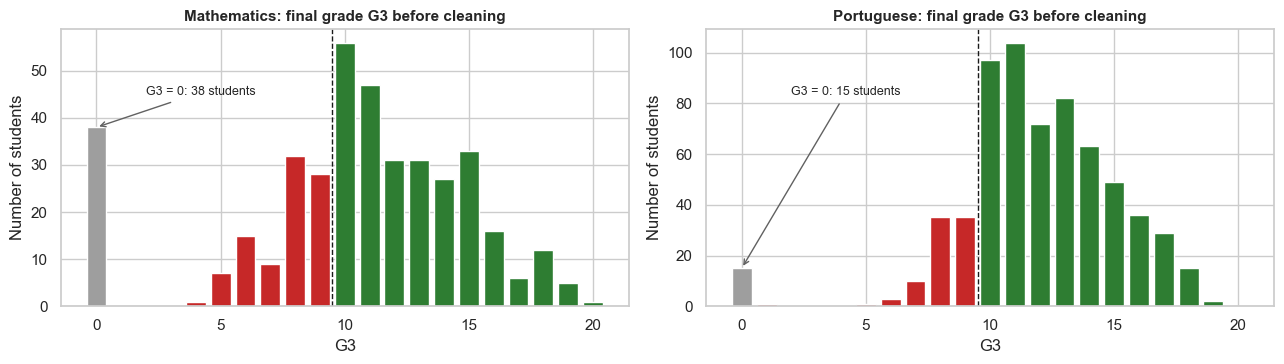

In [3]:
ATURAN_RENTANG = {'age': (15, 22), 'Medu': (0, 4), 'Fedu': (0, 4), 'traveltime': (1, 4), 'studytime': (1, 4),
                  'failures': (0, 3), 'famrel': (1, 5), 'freetime': (1, 5), 'goout': (1, 5), 'Dalc': (1, 5),
                  'Walc': (1, 5), 'health': (1, 5), 'absences': (0, 93), 'G1': (0, 20), 'G2': (0, 20),
                  'G3': (0, 20)}
NILAI_SAH = {'school': {'GP', 'MS'}, 'sex': {'F', 'M'}, 'address': {'U', 'R'}, 'famsize': {'LE3', 'GT3'},
             'Pstatus': {'T', 'A'}, 'Mjob': {'teacher', 'health', 'services', 'at_home', 'other'},
             'Fjob': {'teacher', 'health', 'services', 'at_home', 'other'},
             'reason': {'home', 'reputation', 'course', 'other'}, 'guardian': {'mother', 'father', 'other'}}
for f in FAKTOR:
    if TIPE[f] == 'biner' and f not in NILAI_SAH:
        NILAI_SAH[f] = {'yes', 'no'}


def profil_nilai_nol(df):
    g3 = df.G3 == 0
    return {'Students with a zero in any grade (G1/G2/G3)': int((df[['G1', 'G2', 'G3']] == 0).any(axis=1).sum()),
            'G3 = 0': int(g3.sum()), 'G3 = 0 and G2 = 0': int((g3 & (df.G2 == 0)).sum()),
            'G1 = 0': int((df.G1 == 0).sum()),
            'No absences among students with G3 = 0': pct((df.loc[g3, 'absences'] == 0).mean()) if g3.any() else '-',
            'No absences among other students': pct((df.loc[~g3, 'absences'] == 0).mean())}


def bersihkan(df, nama):
    log = {'dataset': nama, 'n_awal': len(df)}
    df = df.copy()
    for c in ATURAN_RENTANG:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    kolom = KAMUS.kolom.tolist()
    log['missing'] = int(df[kolom].isna().any(axis=1).sum())
    df = df.dropna(subset=kolom)
    log['duplikat'] = int(df.duplicated().sum())
    df = df.drop_duplicates()
    luar = pd.Series(False, index=df.index)
    for c, (lo, hi) in ATURAN_RENTANG.items():
        luar |= (df[c] < lo) | (df[c] > hi)
    for c, sah in NILAI_SAH.items():
        luar |= ~df[c].isin(sah)
    log['tidak_sah'] = int(luar.sum())
    df = df[~luar]
    nol = (df[['G1', 'G2', 'G3']] == 0).any(axis=1)
    log['zero_grade_records_excluded'] = int(nol.sum())
    df = df[~nol].copy()
    for c in ATURAN_RENTANG:
        df[c] = df[c].astype(int)
    log['n_akhir'] = len(df)
    log['total_records_excluded'] = log['n_awal'] - log['n_akhir']
    return df.reset_index(drop=True), log


print('Profile of students with zero grades before exclusion:')
display(pd.DataFrame({n: profil_nilai_nol(d) for n, d in DATA_MENTAH.items()}))

DATA, LOG = {}, []
for nama, df in DATA_MENTAH.items():
    DATA[nama], log = bersihkan(df, nama)
    LOG.append(log)
LOG = pd.DataFrame(LOG)
print('Data-cleaning log:')
display(LOG)
simpan_tabel(LOG, 'A1_log_cleaning')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for ax, (nama, df) in zip(axes, DATA_MENTAH.items()):
    vc = df.G3.value_counts().reindex(range(0, 21), fill_value=0)
    warna = ['#9E9E9E' if v == 0 else (WARNA['Pass'] if v >= a_pass else WARNA['Fail']) for v in vc.index]
    ax.bar(vc.index, vc.values, color=warna)
    ax.axvline(a_pass - 0.5, ls='--', c='k', lw=1)
    ax.annotate(f'G3 = 0: {int(vc[0])} students', xy=(0, vc[0]), xytext=(2, vc.max() * 0.8),
                arrowprops=dict(arrowstyle='->', color='#616161'), fontsize=9)
    ax.set_title(f'{nama}: final grade G3 before cleaning')
    ax.set_xlabel('G3')
    ax.set_ylabel('Number of students')
fig.tight_layout()
simpan(fig, 'A1_g3_before_cleaning')

## A2. Grade Distributions (Goal 2, Histograms)
**What is done:** plot histograms of G1, G2, and G3 after cleaning, with the mean shown as a black line and the passing threshold of 10 shown as a dashed red line.

**How to read the plots:** compare distribution shapes across periods and examine how many students are near the threshold of 10. Students near this threshold are the most likely to change pass/fail status.

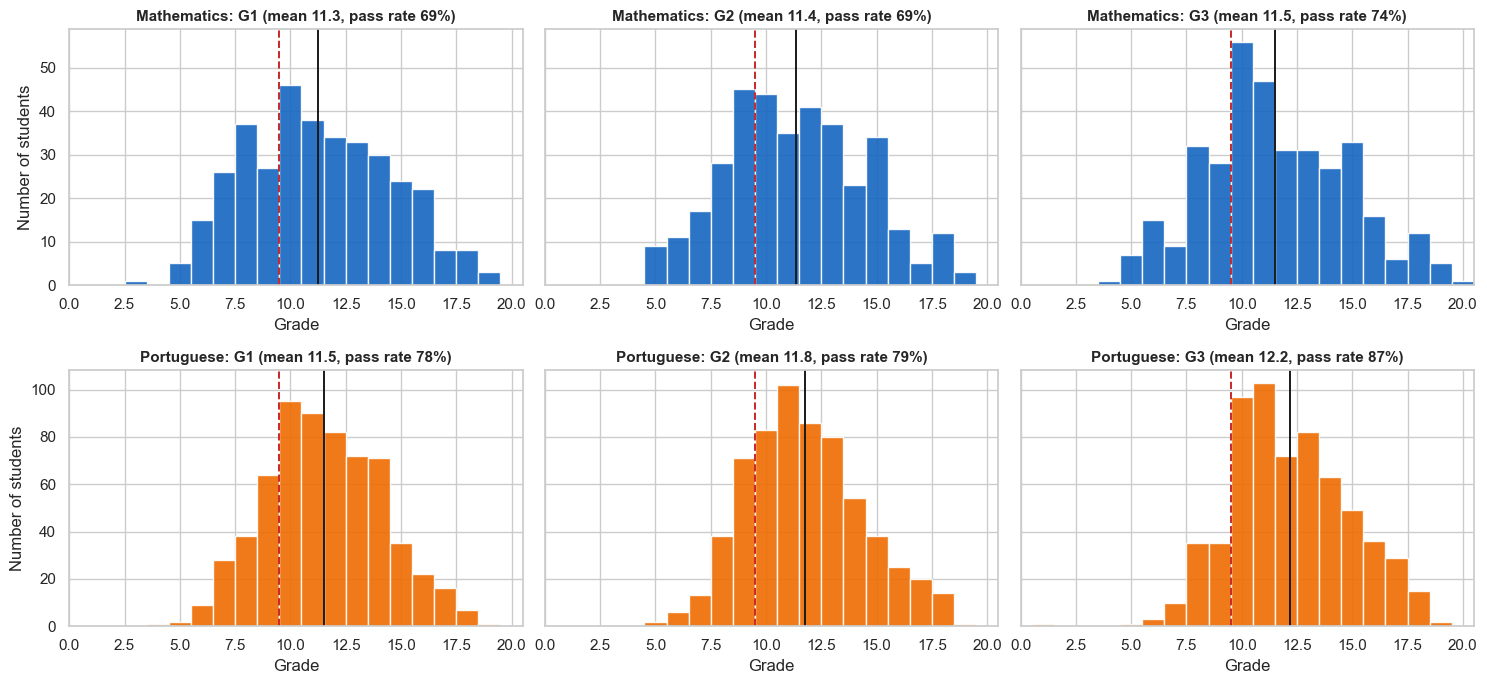

,Mathematics,Portuguese
pass G1,69%,78%
pass G2,69%,79%
pass G3,74%,87%


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey='row')
for i, (nama, df) in enumerate(DATA.items()):
    for j, g in enumerate(['G1', 'G2', 'G3']):
        ax = axes[i, j]
        ax.hist(df[g], bins=np.arange(-0.5, 21.5, 1), color=WARNA[nama], edgecolor='white', alpha=0.9)
        ax.axvline(df[g].mean(), c='k', lw=1.4)
        ax.axvline(a_pass - 0.5, c=WARNA['Fail'], ls='--', lw=1.4)
        ax.set_title(f'{nama}: {g} (mean {angka(df[g].mean(), 1)}, pass rate {pct((df[g] >= a_pass).mean())})')
        ax.set_xlabel('Grade')
        ax.set_xlim(0, 20.5)
        if j == 0:
            ax.set_ylabel('Number of students')
fig.tight_layout()
simpan(fig, 'A2_grade_distribution')

tabel = pd.DataFrame({n: {f'pass {g}': pct((d[g] >= a_pass).mean()) for g in ['G1', 'G2', 'G3']}
                      for n, d in DATA.items()})
display(tabel)

## A3. Previous Grades and Absences versus Final Grade (Goals 2 and 3, Scatter Plots)
**What is done:** create scatter plots for G1 versus G3, G2 versus G3, and `absences` versus G3. Each point represents one student; green indicates passing G3 and red indicates failing G3. The black line is the regression line.

**How to read the plots**
- `r` is the Pearson correlation, while `rho` is the Spearman rank correlation, which is more robust to extreme values.
- Grades are integers, so many points overlap. A small random jitter (±0.25) is added for display only; calculations use the original values.
- **The light-green box in the G1-versus-G3 panel marks the comeback zone:** failing G1 but passing G3. Students in this zone are analyzed in Part B.

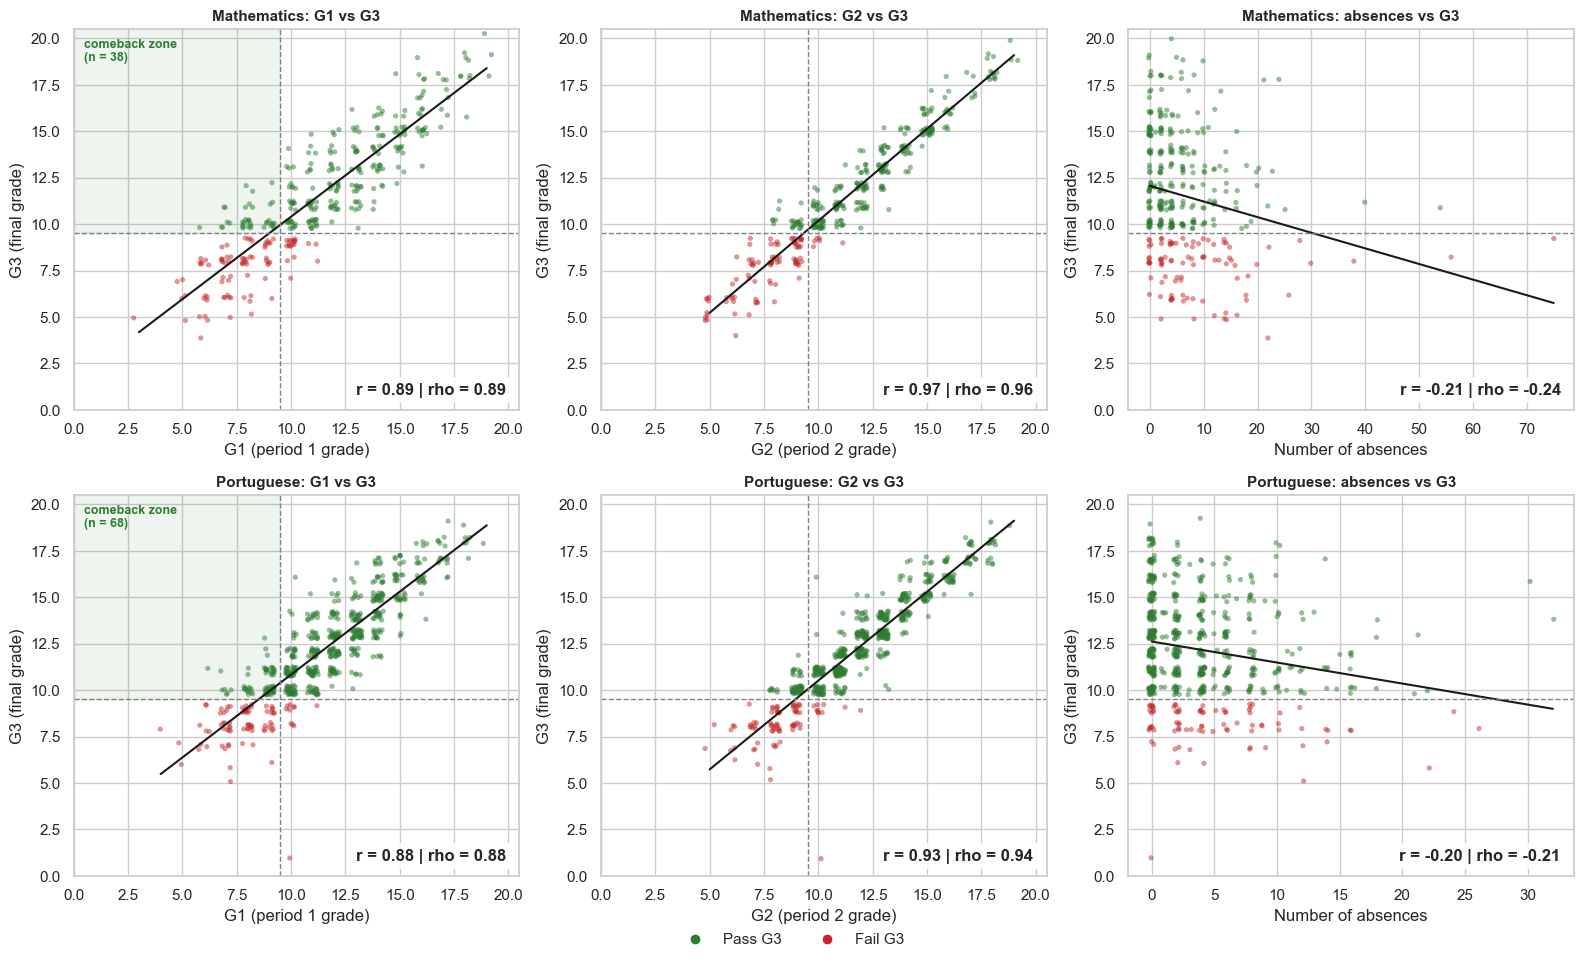

In [5]:
def jitter(x, lebar=0.25):
    return x + RNG.uniform(-lebar, lebar, len(x))


fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for i, (nama, d) in enumerate(DATA.items()):
    is_pass = (d.G3 >= a_pass).to_numpy()
    warna = np.where(is_pass, WARNA['Pass'], WARNA['Fail'])
    for j, (kol, label) in enumerate([('G1', 'G1 (period 1 grade)'), ('G2', 'G2 (period 2 grade)'),
                                      ('absences', 'Number of absences')]):
        ax = axes[i, j]
        x, y = d[kol].astype(float), d.G3.astype(float)
        ax.scatter(jitter(x), jitter(y), c=warna, s=14, alpha=0.5, edgecolor='none')
        k, b = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, k * xs + b, c='k', lw=1.5)
        r, rho = stats.pearsonr(x, y)[0], stats.spearmanr(x, y)[0]
        ax.text(0.97, 0.04, f'r = {angka(r)} | rho = {angka(rho)}', transform=ax.transAxes, ha='right',
                fontweight='bold', bbox=dict(fc='white', ec='none', alpha=0.85))
        ax.axhline(a_pass - 0.5, ls='--', c='grey', lw=1)
        if kol in ('G1', 'G2'):
            ax.axvline(a_pass - 0.5, ls='--', c='grey', lw=1)
            ax.set_xlim(0, 20.5)
        if kol == 'G1':
            n_cb = int(((d.G1 < a_pass) & (d.G3 >= a_pass)).sum())
            ax.add_patch(Rectangle((0, a_pass - 0.5), a_pass - 0.5, 21 - a_pass, color=WARNA['Pass'], alpha=0.08))
            ax.text(0.5, 20, f'comeback zone\n(n = {n_cb})', fontsize=9, va='top', color=WARNA['Pass'],
                    fontweight='bold')
        ax.set_ylim(0, 20.5)
        ax.set_xlabel(label)
        ax.set_ylabel('G3 (final grade)')
        ax.set_title(f'{nama}: {kol} vs G3')
legenda = [Line2D([0], [0], marker='o', lw=0, color=WARNA['Pass'], label='Pass G3'),
           Line2D([0], [0], marker='o', lw=0, color=WARNA['Fail'], label='Fail G3')]
fig.legend(handles=legenda, loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout()
simpan(fig, 'A3_scatter_previous_grades')

## A4. Study Time, Previous Failures, and Absences versus Final Grade (Bar Charts and Box Plots)
**What is done**
- **Bar charts:** mean G3 by study-time category and number of previous failures, with 95% confidence intervals and sample sizes.
- **Box plots:** distribution of G3 by absence groups (0, 1–5, 6–10, and more than 10). These groups are used because `absences` is highly dispersed.

**How to read the plots:** Spearman `rho` in the title indicates the direction and strength of association. Interpret bars with small sample sizes (for example, `failures = 3`) cautiously.

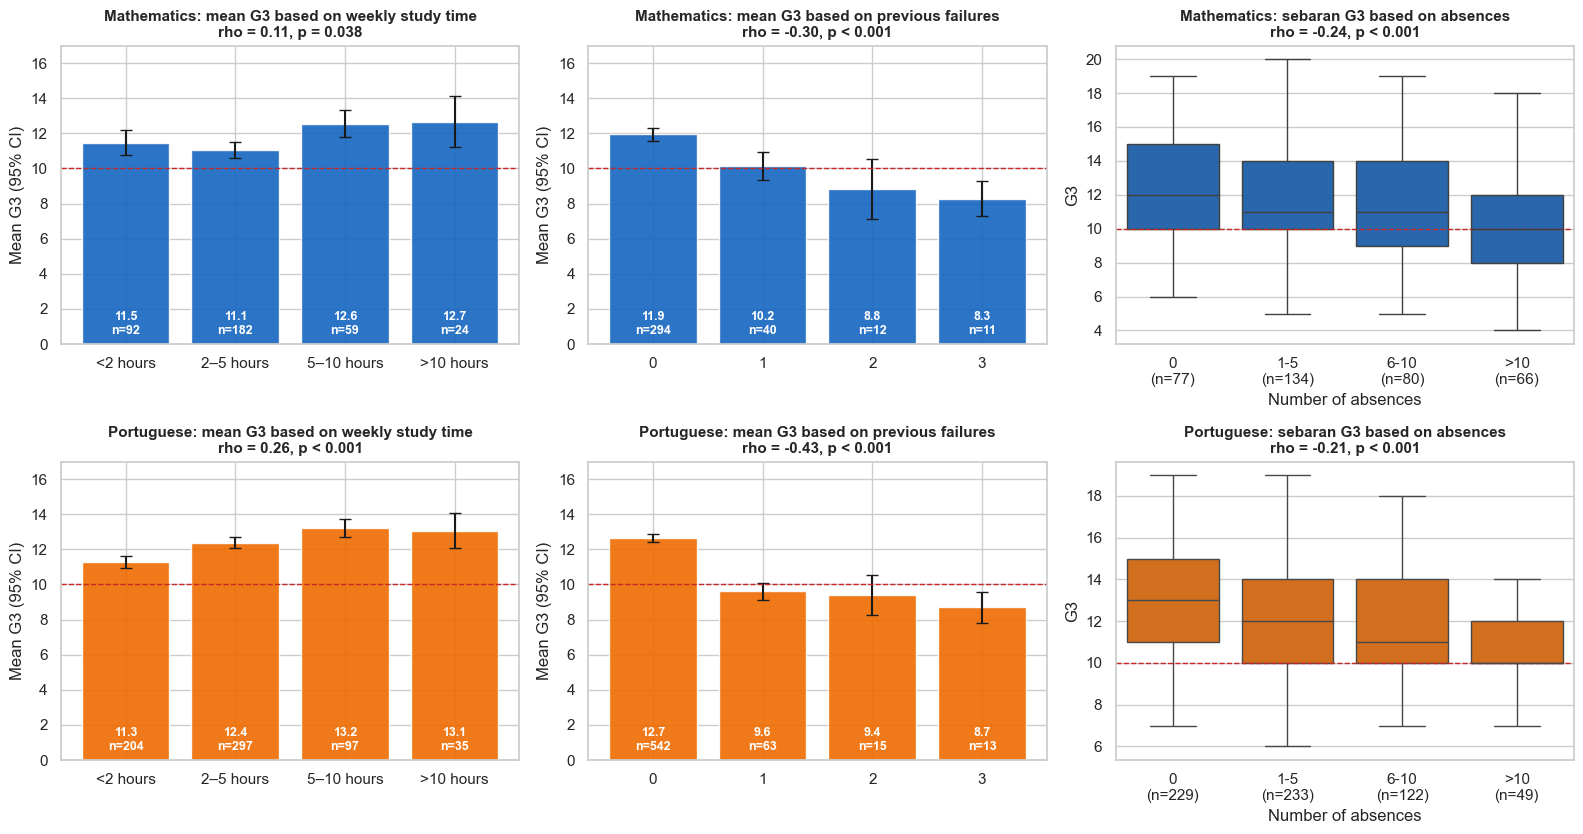

In [6]:
LABEL_STUDY = {1: '<2 hours', 2: '2–5 hours', 3: '5–10 hours', 4: '>10 hours'}
BIN_ABSEN, LABEL_ABSEN = [-1, 0, 5, 10, 100], ['0', '1-5', '6-10', '>10']

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for i, (nama, d) in enumerate(DATA.items()):
    for j, (kol, judul) in enumerate([('studytime', 'weekly study time'),
                                      ('failures', 'previous failures')]):
        ax = axes[i, j]
        g = d.groupby(kol).G3.agg(['mean', 'std', 'count'])
        ci = (1.96 * g['std'] / np.sqrt(g['count'])).fillna(0)
        label = [LABEL_STUDY[v] if kol == 'studytime' else str(v) for v in g.index]
        ax.bar(label, g['mean'], yerr=ci, color=WARNA[nama], capsize=4, alpha=0.9)
        for k_, (m_, n_) in enumerate(zip(g['mean'], g['count'])):
            ax.text(k_, 0.6, f'{angka(m_, 1)}\nn={n_}', ha='center', color='white', fontsize=9, fontweight='bold')
        ax.axhline(a_pass, ls='--', c=WARNA['Fail'], lw=1)
        rho, p = stats.spearmanr(d[kol], d.G3)
        ax.set_title(f'{nama}: mean G3 based on {judul}\nrho = {angka(rho)}, {teks_p("p", p)}')
        ax.set_ylim(0, 17)
        ax.set_ylabel('Mean G3 (95% CI)')
    ax = axes[i, 2]
    kel = pd.cut(d.absences, BIN_ABSEN, labels=LABEL_ABSEN)
    sns.boxplot(x=kel, y=d.G3, order=LABEL_ABSEN, color=WARNA[nama], showfliers=False, ax=ax)
    n_kel = kel.value_counts().reindex(LABEL_ABSEN)
    ax.set_xticks(range(len(LABEL_ABSEN)))
    ax.set_xticklabels([f'{l}\n(n={n_kel[l]})' for l in LABEL_ABSEN])
    ax.axhline(a_pass, ls='--', c=WARNA['Fail'], lw=1)
    rho, p = stats.spearmanr(d.absences, d.G3)
    ax.set_title(f'{nama}: sebaran G3 based on absences\nrho = {angka(rho)}, {teks_p("p", p)}')
    ax.set_xlabel('Number of absences')
    ax.set_ylabel('G3')
fig.tight_layout()
simpan(fig, 'A4_studytime_failures_absences')

## A5. Correlation Heatmaps (Goal 3)
**What is done:** calculate Spearman correlations among all numeric-coded variables (ordinal, numeric, and grade variables).

**Why Spearman:** most variables use scales from 1 to 5, and `absences` is highly skewed. A rank-based correlation is therefore more suitable than Pearson correlation.

**How to read the heatmaps:** red = variables move in the same direction; blue = they move in opposite directions; white = little or no monotonic association. Notice the strongly positive G1, G2, and G3 block.

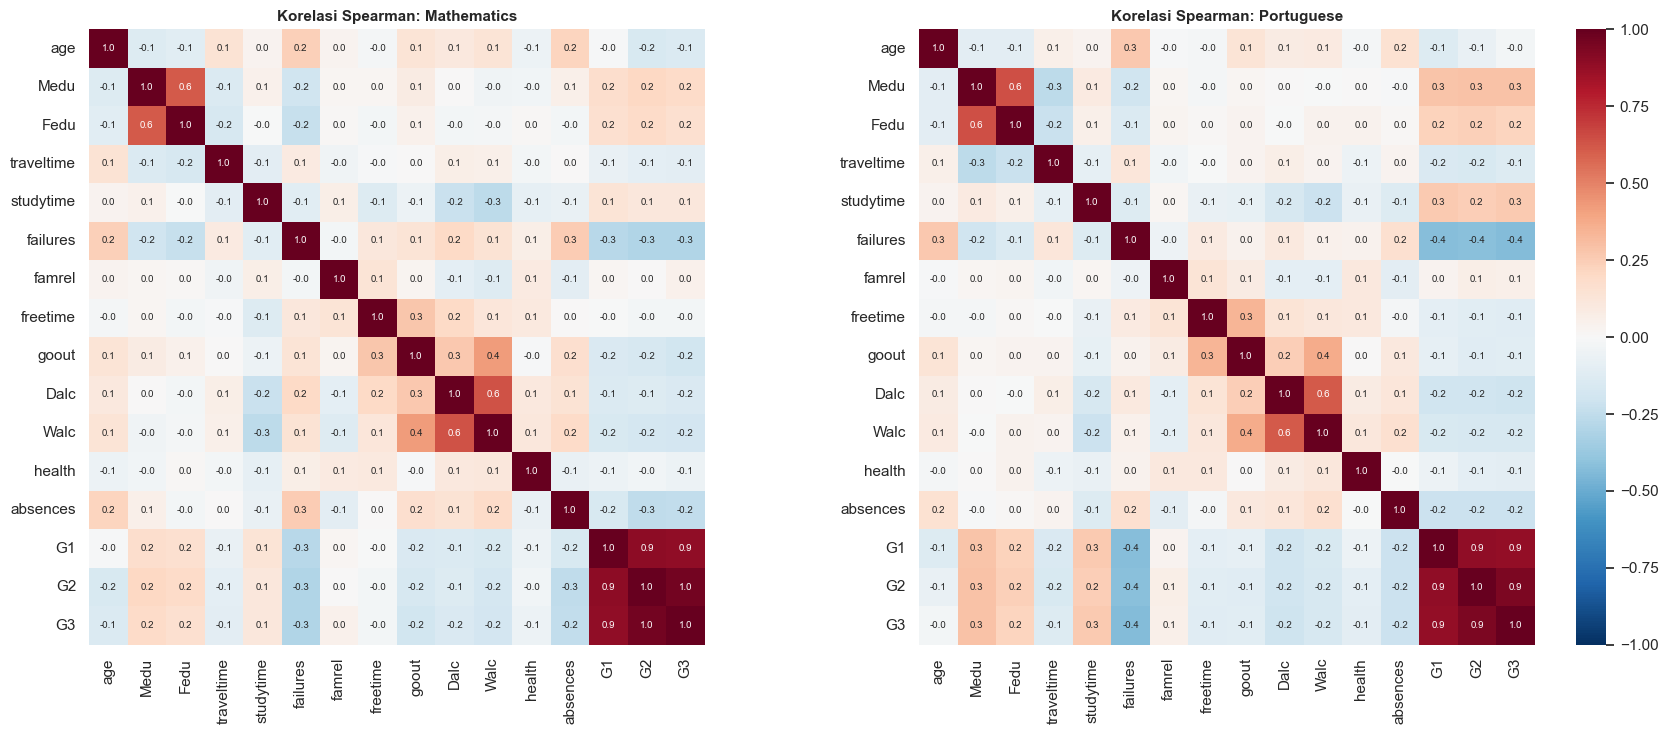

In [7]:
kol_angka = [c for c in KAMUS.kolom if TIPE[c] in ('ordinal', 'numerik', 'nilai')]
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (nama, df) in zip(axes, DATA.items()):
    sns.heatmap(df[kol_angka].corr(method='spearman'), ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                annot=True, fmt='.1f', annot_kws={'size': 7}, square=True, cbar=(ax is axes[-1]))
    ax.set_title(f'Korelasi Spearman: {nama}')
fig.tight_layout()
simpan(fig, 'A5_correlation_heatmap')

## A6. Factors Most Associated with Final Grade G3 (Goal 4)
**What is done**
- **26 binary, ordinal, and numeric factors:** calculate Spearman correlation with G3 (`rho`), then calculate **partial correlation** controlling for G1 (`partial rho`). Partial correlation asks: *is the factor still associated with the final grade after accounting for the student's starting point?*
- **Four nominal factors:** use the Kruskal–Wallis test to assess whether G3 differs across categories.
- Adjust all p-values using the **Benjamini–Hochberg (BH)** procedure because many tests are conducted simultaneously.

**How to read the chart:** dark bars = `rho`; light bars = `partial rho`. `*` indicates significance after correction (q < 0.05), while `†` indicates that the association remains significant after controlling for G1. If the light bar is much shorter, much of the factor’s initial association with G3 may reflect G1.

**Why this matters for Part B:** if G1 explains much of G3, a more useful question is *what distinguishes students whose outcomes change*, rather than simply *what is associated with the final grade*.


=== Mathematics: 10 factors with the largest |rho| with G3 ===


,faktor,tipe,rho,q,rho_parsial,q_parsial
14,failures,ordinal,-0.299,0.000,-0.115,0.129
29,absences,numerik,-0.244,0.000,-0.225,0.000
15,schoolsup,biner,-0.239,0.000,0.013,0.886
6,Medu,ordinal,0.192,0.002,0.080,0.343
25,goout,ordinal,-0.188,0.002,-0.117,0.129
27,Walc,ordinal,-0.187,0.002,-0.097,0.196
7,Fedu,ordinal,0.164,0.008,0.041,0.713
26,Dalc,ordinal,-0.153,0.014,-0.052,0.564
2,age,numerik,-0.148,0.017,-0.293,0.000
3,address,biner,0.127,0.044,0.116,0.129


Mathematics: nominal factors (Kruskal-Wallis against G3)


,faktor,p,q,epsilon2,ringkas
8,Mjob,0.006,0.018,0.040,"lowest at_home (10.8, n=50), highest health (12.9, n=32)"
9,Fjob,0.074,0.134,0.024,"lowest other (11.3, n=196), highest teacher (13.3, n=26)"
10,reason,0.667,0.715,0.004,"lowest course (11.3, n=126), highest reputation (11.8, n=99)"
11,guardian,0.270,0.405,0.007,"lowest other (10.7, n=27), highest father (11.7, n=82)"



=== Portuguese: 10 factors with the largest |rho| with G3 ===


,faktor,tipe,rho,q,rho_parsial,q_parsial
14,failures,ordinal,-0.431,0.000,-0.138,0.007
20,higher,biner,0.347,0.000,0.069,0.215
6,Medu,ordinal,0.290,0.000,0.081,0.187
13,studytime,ordinal,0.264,0.000,0.070,0.215
0,school,biner,-0.250,0.000,-0.027,0.682
7,Fedu,ordinal,0.222,0.000,0.044,0.413
29,absences,numerik,-0.214,0.000,-0.052,0.343
26,Dalc,ordinal,-0.204,0.000,-0.066,0.225
27,Walc,ordinal,-0.167,0.000,-0.057,0.301
3,address,biner,0.146,0.001,0.044,0.413


Portuguese: nominal factors (Kruskal-Wallis against G3)


,faktor,p,q,epsilon2,ringkas
8,Mjob,0.000,0.000,0.059,"lowest at_home (11.4, n=130), highest teacher (13.5, n=70)"
9,Fjob,0.001,0.001,0.031,"lowest at_home (11.7, n=41), highest teacher (14.1, n=34)"
10,reason,0.000,0.000,0.047,"lowest other (11.5, n=67), highest reputation (13.1, n=141)"
11,guardian,0.016,0.024,0.013,"lowest other (11.2, n=40), highest father (12.4, n=150)"


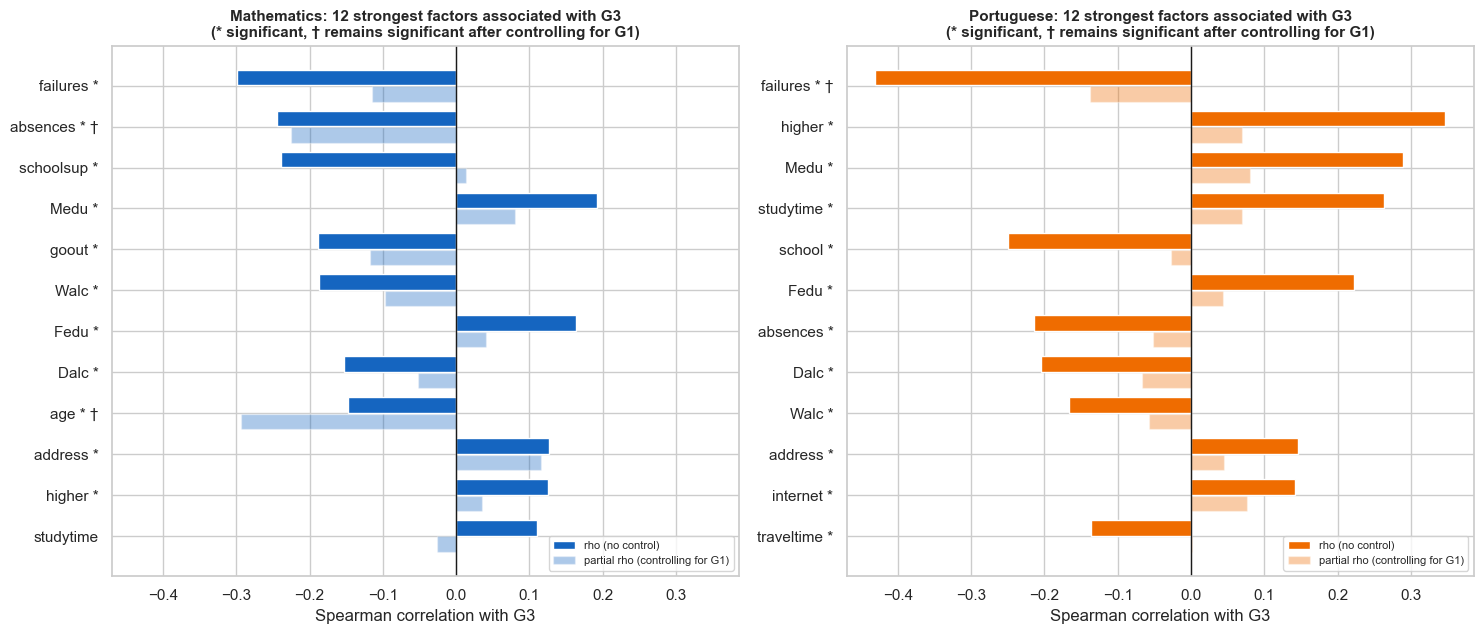

In [8]:
def kodekan_biner(df):
    X = df[FAKTOR].copy()
    for f in FAKTOR:
        if TIPE[f] == 'biner':
            X[f] = (X[f] == LEVEL_POSITIF[f]).astype(int)
    return X


def spearman_parsial(x, y, z):
    # Spearman correlation between x and y after removing the effect of z (rank-based regression)
    rx, ry, rz = (stats.rankdata(np.asarray(v, dtype=float)) for v in (x, y, z))

    def sisa(a, b):
        k, c = np.polyfit(b, a, 1)
        return a - (k * b + c)

    r = np.corrcoef(sisa(rx, rz), sisa(ry, rz))[0, 1]
    n = len(rx)
    t = r * np.sqrt((n - 3) / max(1e-12, 1 - r ** 2))
    return r, 2 * stats.t.sf(abs(t), n - 3)


def faktor_vs_g3(d):
    X = kodekan_biner(d)
    rows = []
    for f in FAKTOR:
        if TIPE[f] == 'nominal':
            grup = [d.G3[d[f] == k] for k in d[f].unique()]
            H, p = stats.kruskal(*grup)
            rerata = d.groupby(f).G3.agg(['mean', 'size']).sort_values('mean')
            rows.append(dict(faktor=f, tipe='nominal', rho=np.nan, p=p, rho_parsial=np.nan, p_parsial=np.nan,
                             epsilon2=H / (len(d) - 1),
                             ringkas=f'lowest {rerata.index[0]} ({angka(rerata["mean"].iloc[0], 1)}, '
                                     f'n={rerata["size"].iloc[0]}), highest {rerata.index[-1]} '
                                     f'({angka(rerata["mean"].iloc[-1], 1)}, n={rerata["size"].iloc[-1]})'))
            continue
        rho, p = stats.spearmanr(X[f], d.G3)
        rp, pp = spearman_parsial(X[f], d.G3, d.G1)
        rows.append(dict(faktor=f, tipe=TIPE[f], rho=rho, p=p, rho_parsial=rp, p_parsial=pp, epsilon2=np.nan,
                         ringkas=''))
    T = pd.DataFrame(rows)
    T['q'] = multipletests(T.p, method='fdr_bh')[1]
    m = T.p_parsial.notna()
    T['q_parsial'] = np.nan
    T.loc[m, 'q_parsial'] = multipletests(T.loc[m, 'p_parsial'], method='fdr_bh')[1]
    T['abs_rho'] = T.rho.abs()
    return T


HASIL_A = {}
for nama, d in DATA.items():
    T = faktor_vs_g3(d)
    HASIL_A[nama] = {'faktor_g3': T, 'r_g1': stats.pearsonr(d.G1, d.G3)[0], 'r_g2': stats.pearsonr(d.G2, d.G3)[0]}
    simpan_tabel(T, f'A6_factors_vs_g3_{KODE[nama]}')
    print(f'\n=== {nama}: 10 factors with the largest |rho| with G3 ===')
    display(T[T.tipe != 'nominal'].nlargest(10, 'abs_rho')[['faktor', 'tipe', 'rho', 'q', 'rho_parsial', 'q_parsial']]
            .round(3))
    print(f'{nama}: nominal factors (Kruskal-Wallis against G3)')
    display(T[T.tipe == 'nominal'][['faktor', 'p', 'q', 'epsilon2', 'ringkas']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True)
for ax, (nama, H) in zip(axes, HASIL_A.items()):
    T = H['faktor_g3']
    T = T[T.tipe != 'nominal'].nlargest(12, 'abs_rho').iloc[::-1]
    y = np.arange(len(T))
    ax.barh(y + 0.2, T.rho, height=0.38, color=WARNA[nama], label='rho (no control)')
    ax.barh(y - 0.2, T.rho_parsial, height=0.38, color=WARNA[nama], alpha=0.35, label='partial rho (controlling for G1)')
    label = [f'{f}{" *" if q < A else ""}{" †" if qp < A else ""}' for f, q, qp in zip(T.faktor, T.q, T.q_parsial)]
    ax.set_yticks(y)
    ax.set_yticklabels(label)
    ax.axvline(0, c='k', lw=1)
    ax.set_title(f'{nama}: 12 strongest factors associated with G3\n(* significant, † remains significant after controlling for G1)')
    ax.set_xlabel('Spearman correlation with G3')
    ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
simpan(fig, 'A6_factors_vs_g3')

### Summary of Part A
The next cell automatically summarizes the basic EDA findings and provides a transition to Part B.

In [9]:
for nama, H in HASIL_A.items():
    T = H['faktor_g3']
    num = T[T.tipe != 'nominal']
    top = num.nlargest(3, 'abs_rho')
    bertahan = num[num.q_parsial < A].sort_values('q_parsial').faktor.tolist()
    nom = T[(T.tipe == 'nominal') & (T.q < A)].faktor.tolist()
    H['top_g3'], H['bertahan'], H['nominal_sig'] = top, bertahan, nom
    print(f'- {nama}: G1–G3 correlation = {angka(H["r_g1"])}, G2-G3 = {angka(H["r_g2"])}. Previous grades '
          'are most strongly associated with the final grade.')
    print(f'  Strongest background-factor associations with G3: '
          + ', '.join(f'{r.faktor} (rho {angka(r.rho)})' for _, r in top.iterrows()) + '.')
    print(f'  Factors remaining significant after controlling for G1: {daftar(bertahan)}.')
    print(f'  Nominal factors associated with G3: {daftar(nom)}.')
print('\nBecause G1 is strongly associated with G3, Part B focuses on students who failed G1 and examines what '
      'distinguishes students who recovered.')

- Mathematics: G1–G3 correlation = 0.89, G2-G3 = 0.97. Previous grades are most strongly associated with the final grade.
  Strongest background-factor associations with G3: failures (rho -0.30), absences (rho -0.24), schoolsup (rho -0.24).
  Factors remaining significant after controlling for G1: age and absences.
  Nominal factors associated with G3: Mjob.
- Portuguese: G1–G3 correlation = 0.88, G2-G3 = 0.93. Previous grades are most strongly associated with the final grade.
  Strongest background-factor associations with G3: failures (rho -0.43), higher (rho 0.35), Medu (rho 0.29).
  Factors remaining significant after controlling for G1: age and failures.
  Nominal factors associated with G3: Mjob, Fjob, reason and guardian.

Because G1 is strongly associated with G3, Part B focuses on students who failed G1 and examines what distinguishes students who recovered.


# Part B. Main Finding: Student Comeback
## B1. Defining the Trajectory Categories (Goal 5)
**What is done:** assign each student a grade trajectory based on pass/fail status (grade ≥ 10) in each period.

| Category | G1 | G2 | G3 | Description |
|---|---|---|---|---|
| Early Comeback | Fail | Pass | Pass | Recovery begins in Period 2 |
| Late Comeback | Fail | Fail | Pass | Recovery occurs in the final period |
| Temporary Comeback | Fail | Pass | Fail | Recovers temporarily, then fails again |
| Persistent Failure | Fail | Fail | Fail | Never reaches a passing grade |

Students with G1 ≥ 10 are labeled Stable Pass or Decline for the overall descriptive analysis.

**Main analysis:** Comeback (Early + Late; passing G3) versus Persistent Failure. Temporary Comeback remains visible in the charts but is excluded from the main comparison because its trajectory differs from the two main groups.

In [10]:
def beri_label(df):
    df = df.copy()
    for g in ['G1', 'G2', 'G3']:
        df[f'pass_{g}'] = df[g] >= a_pass
    l1, l2, l3 = df.pass_G1, df.pass_G2, df.pass_G3
    kondisi = [~l1 & l2 & l3, ~l1 & ~l2 & l3, ~l1 & l2 & ~l3, ~l1 & ~l2 & ~l3, l1 & l3, l1 & ~l3]
    df['kategori'] = np.select(kondisi, URUTAN_SEMUA, default='?')
    df['selisih_G3_G1'] = df.G3 - df.G1
    return df


HASIL = {}
rows = []
for nama, df in DATA.items():
    d = beri_label(df)
    fokus = d[~d.pass_G1].copy()
    kel_fail = ['Persistent Failure'] + (['Temporary Comeback'] if CONFIG['INCLUDE_TEMPORARY_IN_BINARY'] else [])
    biner = fokus[fokus.kategori.isin(['Early Comeback', 'Late Comeback'] + kel_fail)].copy()
    biner['comeback'] = biner.kategori.isin(['Early Comeback', 'Late Comeback']).astype(int)
    HASIL[nama] = {'df': d, 'fokus': fokus, 'biner': biner}
    vc = fokus.kategori.value_counts().reindex(URUTAN_FOKUS, fill_value=0)
    for k, v in vc.items():
        rows.append({'dataset': nama, 'kategori': k, 'n': int(v), 'persen': v / len(fokus)})
KOMPOSISI = pd.DataFrame(rows)
simpan_tabel(KOMPOSISI, 'B1_category_composition')
tampil = KOMPOSISI.assign(persen=KOMPOSISI.persen.map(lambda v: pct(v, 1)))
print('Student categories with G1 < 10:')
display(tampil.pivot(index='kategori', columns='dataset', values=['n', 'persen']).reindex(URUTAN_FOKUS))
for nama, H in HASIL.items():
    b = H['biner']
    print(f'{nama}: {len(H["fokus"])} students failed G1 -> main analysis {int(b.comeback.sum())} Comeback vs '
          f'{int((b.comeback == 0).sum())} Persistent Failure')

Student categories with G1 < 10:


n                 persen           
dataset            Mathematics Portuguese Mathematics Portuguese
kategori                                                        
Early Comeback              20         41       18.0%      28.9%
Late Comeback               18         27       16.2%      19.0%
Temporary Comeback           3          8        2.7%       5.6%
Persistent Failure          70         66       63.1%      46.5%

Mathematics: 111 students failed G1 -> main analysis 38 Comeback vs 70 Persistent Failure
Portuguese: 142 students failed G1 -> main analysis 68 Comeback vs 66 Persistent Failure


## B2. Grade Transition Patterns
**What is done**
- **Interactive Sankey diagram:** shows student flows between pass/fail statuses from G1 to G2 to G3. Band width represents the number of students. An HTML file is saved for presentation or screenshots.
- **Category composition:** shows the proportions of the four categories among students with G1 < 10 in both datasets.
- **Mean trajectories:** shows average G1, G2, and G3 for each category to identify when each group begins to improve.

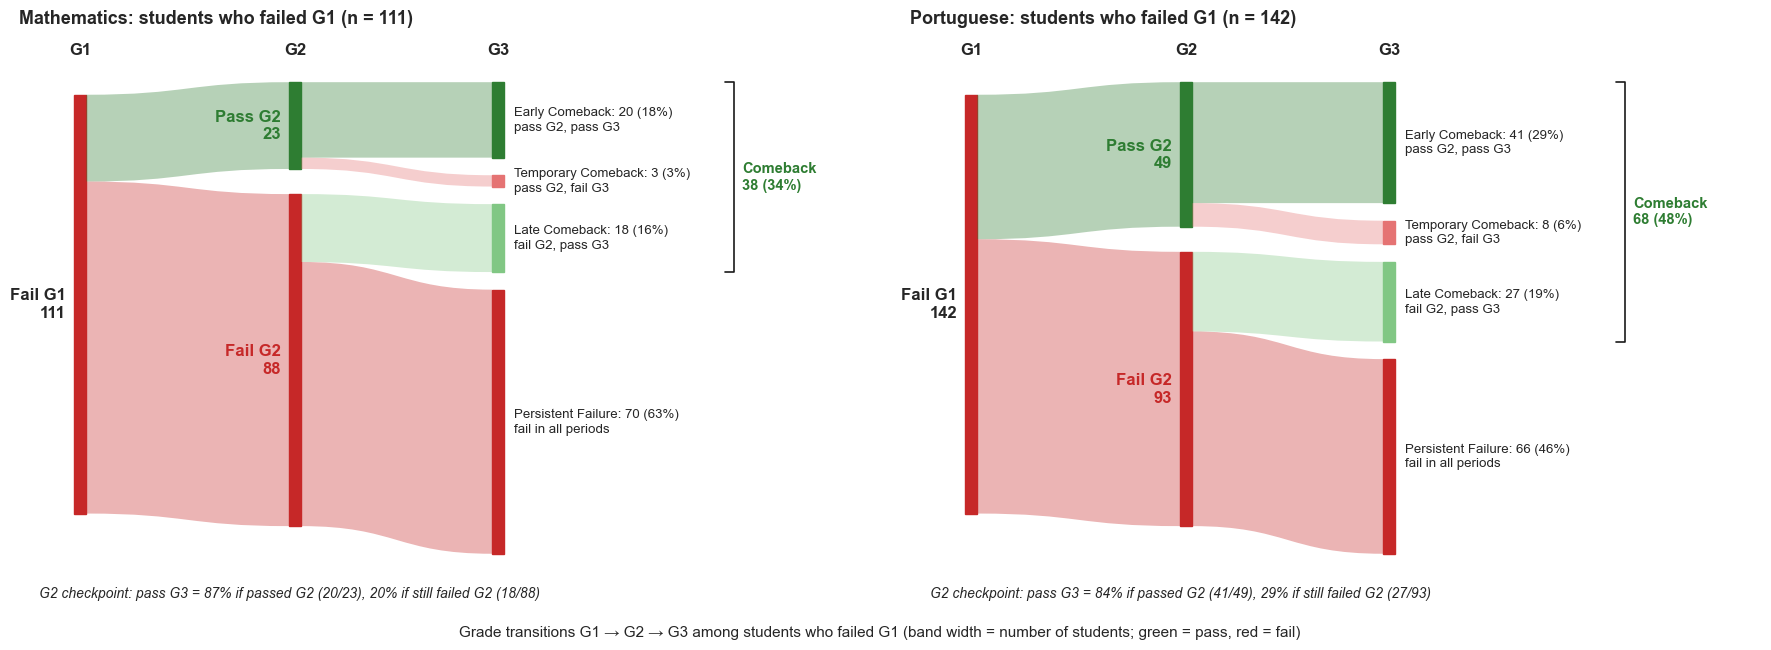

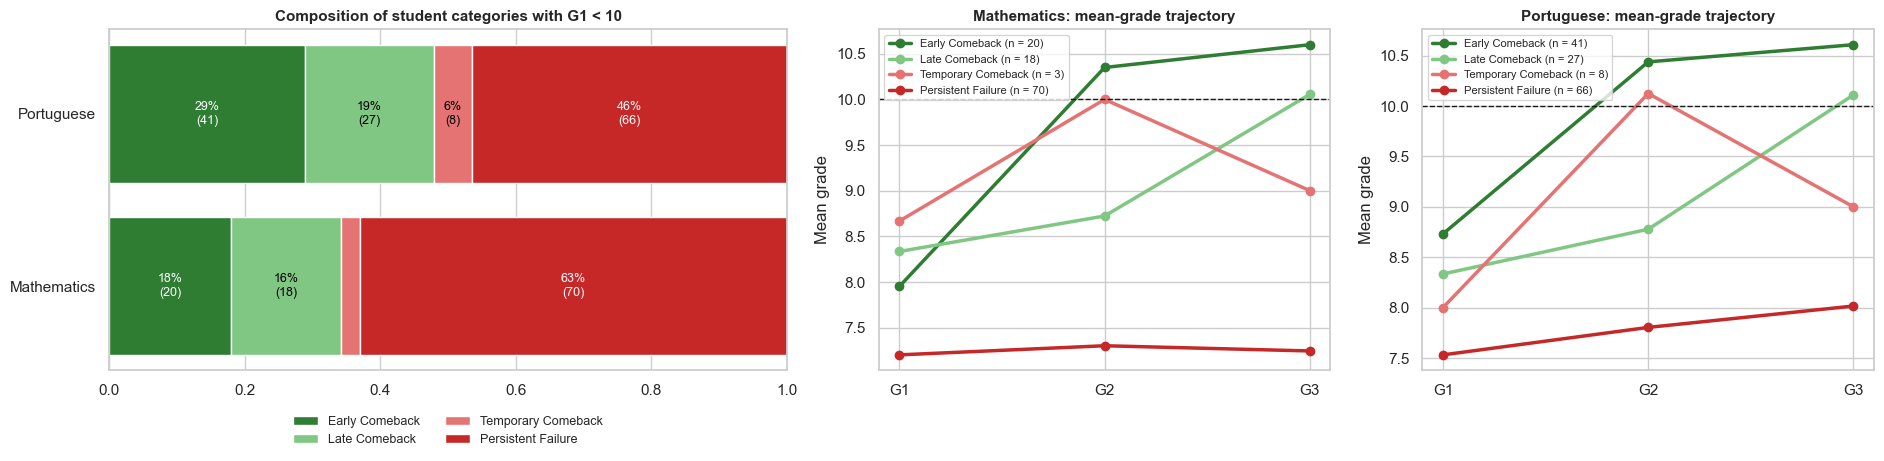

In [11]:
# ===== B2. Grade transition patterns =====
# Part 1: flow diagram of students who failed G1 (G1 -> G2 -> G3)
# Part 2: category composition + mean grade trajectories
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle

C_PASS, C_FAIL = '#2E7D32', '#C62828'
# Urutan URUTAN_FOKUS: [Early Comeback, Late Comeback, Temporary Comeback, Persistent Failure]
K_EARLY, K_LATE, K_TEMP, K_PERS = URUTAN_FOKUS


def pita(ax, x0, y0a, y0b, x1, y1a, y1b, warna, alpha=0.35):
    # Curved band from left node to right node; band width = number of students
    xm = (x0 + x1) / 2
    verts = [(x0, y0a), (xm, y0a), (xm, y1a), (x1, y1a), (x1, y1b), (xm, y1b), (xm, y0b), (x0, y0b), (x0, y0a)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
    ax.add_patch(PathPatch(Path(verts, codes), fc=warna, ec='none', alpha=alpha))


def gambar_alur(f_, nama, ax):
    n_all = len(f_)
    hit = f_.kategori.value_counts().reindex(URUTAN_FOKUS, fill_value=0)
    e, l, t, p = (int(hit[k]) for k in [K_EARLY, K_LATE, K_TEMP, K_PERS])
    g2p, g2f = e + t, l + p          # pass G2 = early + temporary; fail G2 = late + persistent
    cb = e + l                       # total comeback
    gap, W = n_all * 0.06, 0.18
    X = [1.0, 4.0, 7.0]

    # G1 and G2 nodes
    tinggi_g2 = g2p + gap + g2f
    y_g1 = (tinggi_g2 - n_all) / 2
    ax.add_patch(Rectangle((X[0] - W, y_g1), W, n_all, color=C_FAIL))
    ax.add_patch(Rectangle((X[1], 0), W, g2p, color=C_PASS))
    ax.add_patch(Rectangle((X[1], g2p + gap), W, g2f, color=C_FAIL))
    pita(ax, X[0], y_g1, y_g1 + g2p, X[1], 0, g2p, C_PASS)
    pita(ax, X[0], y_g1 + g2p, y_g1 + n_all, X[1], g2p + gap, tinggi_g2, C_FAIL)

    # G3 nodes = four trajectory categories (same colours as the composition chart)
    ujung, y = [], 0
    for k, n, asal, ket in [(K_EARLY, e, 'p', 'pass G2, pass G3'), (K_TEMP, t, 'p', 'pass G2, fail G3'),
                            (K_LATE, l, 'f', 'fail G2, pass G3'), (K_PERS, p, 'f', 'fail in all periods')]:
        ujung.append((k, n, asal, ket, y))
        y += n + gap * 0.7
    offset = {'p': 0, 'f': g2p + gap}
    for k, n, asal, ket, yy in ujung:
        if n == 0:
            continue
        ax.add_patch(Rectangle((X[2], yy), W, n, color=WARNA[k]))
        pita(ax, X[1] + W, offset[asal], offset[asal] + n, X[2], yy, yy + n, WARNA[k])
        offset[asal] += n
        ax.text(X[2] + W + 0.15, yy + n / 2, f'{k}: {n} ({pct(n / n_all)})\n{ket}',
                va='center', fontsize=9.5, linespacing=1.3)

    # Kurung total comeback (Early + Late)
    y_top, y_bot = ujung[0][4], ujung[2][4] + l
    xb = 10.45
    ax.plot([xb, xb + 0.12, xb + 0.12, xb], [y_top, y_top, y_bot, y_bot], color='k', lw=1.2)
    ax.text(xb + 0.25, (y_top + y_bot) / 2, f'Comeback\n{cb} ({pct(cb / n_all)})',
            va='center', fontsize=10.5, fontweight='bold', color=C_PASS)

    # Node labels and G2 checkpoint
    ax.text(X[0] - W - 0.12, y_g1 + n_all / 2, f'Fail G1\n{n_all}', ha='right', va='center', fontweight='bold')
    ax.text(X[1] - 0.12, g2p / 2, f'Pass G2\n{g2p}', ha='right', va='center', fontweight='bold', color=C_PASS)
    ax.text(X[1] - 0.12, g2p + gap + g2f / 2, f'Fail G2\n{g2f}', ha='right', va='center', fontweight='bold', color=C_FAIL)
    for x, g in zip(X, ['G1', 'G2', 'G3']):
        ax.text(x - W / 2 if g == 'G1' else x + W / 2, -gap * 1.1, g, ha='center', fontsize=12, fontweight='bold')
    teks = (f'G2 checkpoint: pass G3 = {pct(e / g2p)} if passed G2 ({e}/{g2p}), '
            f'{pct(l / g2f)} if still failed G2 ({l}/{g2f})')
    ax.text(0.3, max(y, tinggi_g2) + gap * 0.6, teks, fontsize=10, style='italic', va='top')

    ax.set_xlim(0, 12.6)
    ax.set_ylim(max(y, tinggi_g2) + gap * 2, -gap * 2)
    ax.axis('off')
    ax.set_title(f'{nama}: students who failed G1 (n = {n_all})', fontsize=13, fontweight='bold', loc='left')


# ---- Part 1: flow diagram ----
fig, axes = plt.subplots(1, 2, figsize=(18, 6.8))
for ax, (nama, H) in zip(axes, HASIL.items()):
    gambar_alur(H['fokus'], nama, ax)
fig.suptitle('Grade transitions G1 → G2 → G3 among students who failed G1 '
             '(band width = number of students; green = pass, red = fail)', fontsize=11, y=0.02)
fig.tight_layout()
simpan(fig, 'B2_transition_flow_failed_g1')

# ---- Part 2: category composition + mean grade trajectories ----
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={'width_ratios': [1.5, 1, 1]})
ax = axes[0]
komp = KOMPOSISI.pivot(index='dataset', columns='kategori', values='n')[URUTAN_FOKUS]
prop = komp.div(komp.sum(1), axis=0)
kiri = np.zeros(len(prop))
for k in URUTAN_FOKUS:
    ax.barh(prop.index, prop[k], left=kiri, color=WARNA[k], label=k, edgecolor='white')
    for i, (v, l) in enumerate(zip(prop[k], kiri)):
        if v >= 0.05:
            ax.text(l + v / 2, i, f'{pct(v)}\n({komp[k].iloc[i]})', ha='center', va='center', fontsize=9,
                    color='black' if k in (K_LATE, K_TEMP) else 'white')
    kiri += prop[k].values
ax.set_xlim(0, 1)
ax.set_title('Composition of student categories with G1 < 10')
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=9)

for ax, (nama, H) in zip(axes[1:], HASIL.items()):
    f_ = H['fokus']
    ada = [k for k in URUTAN_FOKUS if (f_.kategori == k).any()]
    rata = f_.groupby('kategori')[['G1', 'G2', 'G3']].mean().reindex(ada)
    n = f_.kategori.value_counts()
    for k, r in rata.iterrows():
        ax.plot(['G1', 'G2', 'G3'], r.values, marker='o', lw=2.5, color=WARNA[k], label=f'{k} (n = {n[k]})')
    ax.axhline(a_pass, ls='--', c='k', lw=1)
    ax.set_title(f'{nama}: mean-grade trajectory')
    ax.set_ylabel('Mean grade')
    ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
simpan(fig, 'B2_composition_and_trajectories')

## B3. G2 as a Checkpoint
**What is done:** calculate the probability of passing G3 among students who failed G1, stratified by their G2 status, with 95% Wilson confidence intervals.

**Why analyze this separately from the factors:** G2 is part of the trajectory definition, so it should not be tested as an independent factor (to avoid data leakage). Instead, G2 is used as a second checkpoint for schools.

,dataset,status G2,n,pass G3,peluang pass G3,CI lower,CI upper
0,Mathematics,Pass G2,23,20,0.870,0.679,0.955
1,Mathematics,Fail G2,88,18,0.205,0.133,0.300
2,Portuguese,Pass G2,49,41,0.837,0.710,0.915
3,Portuguese,Fail G2,93,27,0.290,0.208,0.389


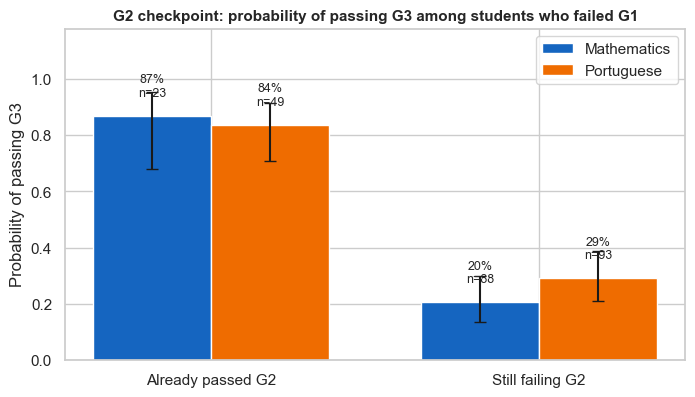

In [12]:
rows = []
for nama, H in HASIL.items():
    f_ = H['fokus']
    tab = []
    for pass_g2 in [True, False]:
        sub = f_[f_.pass_G2 == pass_g2]
        k, n = int(sub.pass_G3.sum()), len(sub)
        lo, hi = proportion_confint(k, n, method='wilson') if n else (np.nan, np.nan)
        rows.append({'dataset': nama, 'status G2': 'Pass G2' if pass_g2 else 'Fail G2', 'n': n, 'pass G3': k,
                     'peluang pass G3': k / n if n else np.nan, 'CI lower': lo, 'CI upper': hi})
        tab.append([k, n - k])
    H['g2_p'] = stats.fisher_exact(tab)[1]
G2 = pd.DataFrame(rows)
for nama, H in HASIL.items():
    H['g2'] = G2[G2.dataset == nama].set_index('status G2')
display(G2.round(3))
simpan_tabel(G2, 'B3_checkpoint_g2')

fig, ax = plt.subplots(figsize=(8, 4.3))
lebar = 0.36
for i, nama in enumerate(HASIL):
    d = G2[G2.dataset == nama]
    xpos = np.arange(2) + (i - 0.5) * lebar
    p_ = d['peluang pass G3'].to_numpy()
    ax.bar(xpos, p_, width=lebar, color=WARNA[nama], label=nama,
           yerr=[np.clip(p_ - d['CI lower'], 0, None), np.clip(d['CI upper'] - p_, 0, None)], capsize=4)
    for x_, v, n in zip(xpos, p_, d['n']):
        ax.text(x_, v + 0.07, f'{pct(v)}\nn={n}', ha='center', fontsize=9)
ax.set_xticks(np.arange(2))
ax.set_xticklabels(['Already passed G2', 'Still failing G2'])
ax.set_ylim(0, 1.18)
ax.set_ylabel('Probability of passing G3')
ax.set_title('G2 checkpoint: probability of passing G3 among students who failed G1')
ax.legend()
simpan(fig, 'B3_checkpoint_g2')

## B4. Comparing 30 Factors: Comeback versus Persistent Failure
**What is done:** test each factor using a method appropriate to its data type, then calculate an effect size so differences can be compared.

| Factor type | Test (whether groups differ) | Effect size (magnitude of difference) |
|---|---|---|
| Ordinal and numeric | Mann–Whitney U | Signed rank-biserial r (equivalent to Cliff’s delta in interpretation) |
| Binary | Fisher’s exact test | Signed phi |
| Nominal | Chi-square, or permutation test when cells are small | Bias-corrected Cramér’s V (unsigned) |

A positive sign means the factor value is higher or more frequent among comeback students. Approximate effect-size benchmarks: 0.1 small, 0.3 medium, and 0.5 large.

**Multiple-testing correction:** conducting 30 tests simultaneously increases the chance that some results appear significant by chance. The decision uses **Benjamini–Hochberg** because this is exploratory analysis. The stricter **Holm** correction is also reported for comparison; factors that pass BH but not Holm are marked as “sensitive to the correction method.”

**Status:** Pass if q < 0.05 and |effect| ≥ 0.20. Suggestive if q < 0.10 and |effect| ≥ 0.20.

**Factor preparation:** nominal categories with fewer than 10 students are combined into `other`, and factors where one value accounts for more than 95% are excluded. These rules depend only on frequencies, not comeback outcomes. Effect-size uncertainty is estimated using **bootstrap** resampling (1,000 resamples per group).


=== Mathematics: 30 factors tested, 3 pass, 0 suggestive ===
   note: Mjob: categories ['health'] merged into "other"
   note: Fjob: categories ['at_home', 'teacher', 'health'] merged into "other"


,faktor,tipe,uji,efek,CI95_bawah,CI95_atas,q,p_holm,status,catatan,ringkas
0,absences,numerik,Mann-Whitney U,-0.406,-0.594,-0.207,0.007,0.014,Passes criteria,,median 4 vs 6.5; mean 4.05 vs 9.41
1,goout,ordinal,Mann-Whitney U,-0.399,-0.617,-0.204,0.007,0.013,Passes criteria,,median 2.5 vs 4; mean 2.74 vs 3.51
2,age,numerik,Mann-Whitney U,-0.364,-0.544,-0.171,0.014,0.040,Passes criteria,,median 16 vs 17; mean 16.16 vs 17.04
3,failures,ordinal,Mann-Whitney U,-0.212,-0.391,-0.026,0.225,0.809,Not significant,,median 0 vs 0; mean 0.39 vs 0.71
4,romantic,biner,Fisher exact,-0.201,-0.359,-0.024,0.236,1.000,Not significant,,comeback rate romantic = yes: 19% vs no: 41%
5,famrel,ordinal,Mann-Whitney U,0.170,-0.045,0.366,0.545,1.000,Not significant,,median 4 vs 4; mean 4.16 vs 3.86
6,school,biner,Fisher exact,-0.153,-0.290,0.008,0.545,1.000,Not significant,,comeback rate school = MS: 15% vs GP: 38%
7,Fjob,nominal,Chi-square,0.102,0.000,0.307,0.545,1.000,Not significant,,"comeback rate: other 39%, services 24%"
8,guardian,nominal,Permutation chi-square,0.103,0.000,0.276,0.644,1.000,Not significant,,"comeback rate: mother 38%, father 35%, other 10%"
9,activities,biner,Fisher exact,0.119,-0.074,0.309,0.699,1.000,Not significant,,comeback rate activities = yes: 41% vs no: 30%



=== Portuguese: 30 factors tested, 0 pass, 0 suggestive ===
   note: Mjob: categories ['health', 'teacher'] merged into "other"
   note: Fjob: categories ['health', 'teacher'] merged into "other"


,faktor,tipe,uji,efek,CI95_bawah,CI95_atas,q,p_holm,status,catatan,ringkas
0,Mjob,nominal,Chi-square,0.217,0.000,0.382,0.482,0.482,Not significant,,"comeback rate: other 58%, at_home 51%, services 21%"
1,absences,numerik,Mann-Whitney U,-0.185,-0.364,-0.002,0.730,1.000,Not significant,,median 4 vs 4; mean 4.31 vs 6.20
2,goout,ordinal,Mann-Whitney U,-0.158,-0.338,0.017,0.730,1.000,Not significant,,median 3 vs 4; mean 3.13 vs 3.48
3,traveltime,ordinal,Mann-Whitney U,0.140,-0.037,0.314,0.730,1.000,Not significant,,median 2 vs 1; mean 1.82 vs 1.65
4,failures,ordinal,Mann-Whitney U,-0.131,-0.290,0.045,0.730,1.000,Not significant,,median 0 vs 1; mean 0.57 vs 0.80
5,school,biner,Fisher exact,-0.121,-0.290,0.044,0.730,1.000,Not significant,,comeback rate school = MS: 45% vs GP: 57%
6,paid,biner,Fisher exact,-0.118,-0.256,0.048,0.730,1.000,Not significant,,comeback rate paid = yes: 30% vs no: 52%
7,schoolsup,biner,Fisher exact,0.113,-0.054,0.257,0.730,1.000,Not significant,,comeback rate schoolsup = yes: 67% vs no: 49%
8,romantic,biner,Fisher exact,-0.104,-0.285,0.065,0.730,1.000,Not significant,,comeback rate romantic = yes: 44% vs no: 55%
9,Pstatus,biner,Fisher exact,0.103,-0.071,0.264,0.730,1.000,Not significant,,comeback rate Pstatus = T: 52% vs A: 36%


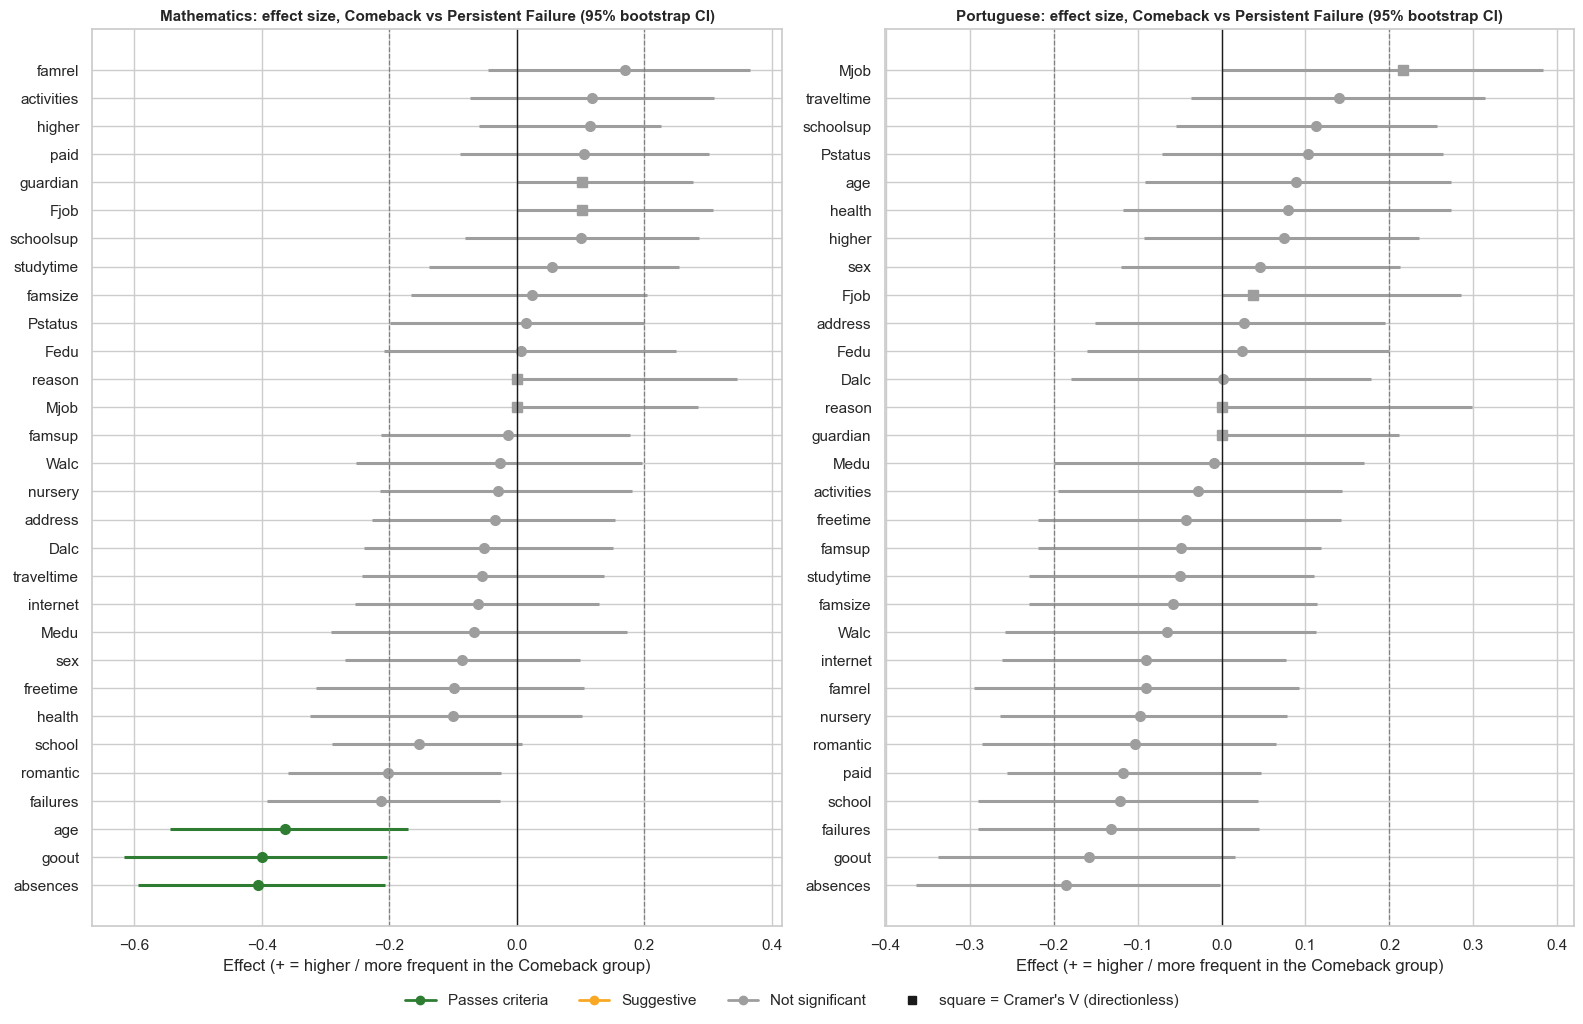

In [13]:
def siapkan_faktor(fokus):
    X = pd.DataFrame(index=fokus.index)
    aktif, catatan = [], []
    for f in FAKTOR:
        s = fokus[f].copy()
        if TIPE[f] == 'nominal':
            vc = s.value_counts()
            jarang = vc[vc < CONFIG['MIN_N_KATEGORI']].index.tolist()
            if jarang:
                s = s.where(~s.isin(jarang), 'other')
                catatan.append(f'{f}: categories {jarang} merged into "other"')
        dominan = s.value_counts(normalize=True).iloc[0]
        if s.nunique() < 2 or dominan > CONFIG['BATAS_DOMINAN']:
            catatan.append(f'{f}: excluded because one category dominates ({pct(dominan)})')
            continue
        X[f] = (s == LEVEL_POSITIF[f]).astype(int) if TIPE[f] == 'biner' else s
        aktif.append(f)
    return X, aktif, catatan


def chi2_stat(t):
    t = np.asarray(t, dtype=float)
    e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
    with np.errstate(divide='ignore', invalid='ignore'):
        return float(np.where(e > 0, (t - e) ** 2 / e, 0.0).sum())


def cramers_v_koreksi(chi2, n, r, k):
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rk, kk = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    d = min(rk - 1, kk - 1)
    return float(np.sqrt(phi2 / d)) if d > 0 else np.nan


def kode_kategori(x):
    return np.unique(np.asarray(x).astype(str), return_inverse=True)[1].ravel()


def hitung_efek(x, y, tipe):
    x, y = np.asarray(x), np.asarray(y).astype(int)
    n1 = int(y.sum())
    n0 = len(y) - n1
    if n1 < 2 or n0 < 2:
        return np.nan
    if tipe in ('ordinal', 'numerik'):
        rk = stats.rankdata(x.astype(float))
        return 2 * (rk[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) - 1
    if tipe == 'biner':
        x = x.astype(float)
        return np.nan if x.std() == 0 else float(np.corrcoef(x, y)[0, 1])
    kode = kode_kategori(x)
    k = kode.max() + 1
    t = np.bincount(kode * 2 + y, minlength=2 * k).reshape(k, 2)
    return cramers_v_koreksi(chi2_stat(t), len(y), k, 2) if k > 1 else np.nan


def uji_kontingensi(x, g):
    xk, gk = kode_kategori(x), kode_kategori(g)
    kx, kg = xk.max() + 1, gk.max() + 1
    t = np.bincount(xk * kg + gk, minlength=kx * kg).reshape(kx, kg)
    chi2 = chi2_stat(t)
    e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
    if (e < 5).any():
        hit = sum(chi2_stat(np.bincount(xk * kg + RNG.permutation(gk), minlength=kx * kg).reshape(kx, kg))
                  >= chi2 - 1e-9 for _ in range(CONFIG['N_PERMUTASI']))
        return chi2, (hit + 1) / (CONFIG['N_PERMUTASI'] + 1), 'Permutation chi-square'
    return chi2, float(stats.chi2.sf(chi2, (kx - 1) * (kg - 1))), 'Chi-square'


def uji_semua_faktor(X, y, aktif):
    y = pd.Series(np.asarray(y).astype(int), index=X.index)
    baris = []
    for f in aktif:
        tipe, x = TIPE[f], X[f]
        x1, x0 = x[y == 1], x[y == 0]
        if tipe in ('ordinal', 'numerik'):
            p = stats.mannwhitneyu(x1.astype(float), x0.astype(float), alternative='two-sided')[1]
            uji, ringkas = 'Mann-Whitney U', f'median {x1.median():g} vs {x0.median():g}; mean {x1.mean():.2f} vs {x0.mean():.2f}'
        elif tipe == 'biner':
            tab = [[int(((x == 1) & (y == 1)).sum()), int(((x == 1) & (y == 0)).sum())],
                   [int(((x == 0) & (y == 1)).sum()), int(((x == 0) & (y == 0)).sum())]]
            p = stats.fisher_exact(tab)[1]
            uji = 'Fisher exact'
            ringkas = (f'comeback rate {f} = {LEVEL_POSITIF[f]}: {pct(y[x == 1].mean())} '
                       f'vs {LEVEL_NEGATIF[f]}: {pct(y[x == 0].mean())}')
        else:
            _, p, uji = uji_kontingensi(x, y)
            laju = y.groupby(x).mean().sort_values(ascending=False)
            ringkas = 'comeback rate: ' + ', '.join(f'{k} {pct(v)}' for k, v in laju.items())
        baris.append(dict(faktor=f, tipe=tipe, peran=PERAN[f], uji=uji, p=p, efek=hitung_efek(x, y, tipe),
                          ringkas=ringkas))
    T = pd.DataFrame(baris)
    T['q'] = multipletests(T.p, method='fdr_bh')[1]
    T['p_holm'] = multipletests(T.p, method='holm')[1]
    T['efek_abs'] = T.efek.abs()
    T['status'] = np.select([(T.q < A) & (T.efek_abs >= E), (T.q < AI) & (T.efek_abs >= E)],
                            ['Passes criteria', 'Suggestive'], 'Not significant')
    T['catatan'] = np.where((T.status == 'Passes criteria') & (T.p_holm >= A), 'sensitive to correction method', '')
    return T.sort_values(['q', 'efek_abs'], ascending=[True, False]).reset_index(drop=True)


def bootstrap_efek(X, y, aktif, efek_penuh, B):
    y = np.asarray(y).astype(int)
    i1, i0 = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    arr = {f: (kode_kategori(X[f]) if TIPE[f] == 'nominal' else X[f].to_numpy()) for f in aktif}
    hasil = np.full((B, len(aktif)), np.nan)
    for b in range(B):
        s = np.concatenate([RNG.choice(i1, len(i1)), RNG.choice(i0, len(i0))])
        for j, f in enumerate(aktif):
            hasil[b, j] = hitung_efek(arr[f][s], y[s], TIPE[f])
    rows = []
    for j, f in enumerate(aktif):
        e = hasil[:, j][~np.isnan(hasil[:, j])]
        ef = efek_penuh[f]
        stabil = np.mean(e >= E) if TIPE[f] == 'nominal' else np.mean((np.sign(e) == np.sign(ef)) & (np.abs(e) >= E))
        rows.append(dict(faktor=f, CI95_bawah=np.percentile(e, 2.5), CI95_atas=np.percentile(e, 97.5),
                         stabilitas=stabil))
    return pd.DataFrame(rows)


for nama, H in HASIL.items():
    X, aktif, catatan = siapkan_faktor(H['fokus'])
    H['X_fokus'], H['aktif'] = X, aktif
    H['X'], H['y'] = X.loc[H['biner'].index], H['biner']['comeback']
    T = uji_semua_faktor(H['X'], H['y'], aktif)
    H['boot'] = bootstrap_efek(H['X'], H['y'], aktif, T.set_index('faktor').efek, CONFIG['N_BOOTSTRAP'])
    H['uji'] = T.merge(H['boot'], on='faktor')
    simpan_tabel(H['uji'], f'B4_factor_tests_{KODE[nama]}')
    print(f'\n=== {nama}: {len(aktif)} factors tested, {(T.status == "Passes criteria").sum()} pass, '
          f'{(T.status == "Suggestive").sum()} suggestive ===')
    for c in catatan:
        print('   note:', c)
    display(H['uji'][['faktor', 'tipe', 'uji', 'efek', 'CI95_bawah', 'CI95_atas', 'q', 'p_holm', 'status',
                      'catatan', 'ringkas']].head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
for ax, (nama, H) in zip(axes, HASIL.items()):
    T = H['uji'].sort_values('efek').reset_index(drop=True)
    ypos = np.arange(len(T))
    warna = T.status.map(WARNA_STATUS)
    ax.hlines(ypos, T.CI95_bawah, T.CI95_atas, color=warna, lw=2.2)
    for yy, e, c, t in zip(ypos, T.efek, warna, T.tipe):
        ax.plot(e, yy, 's' if t == 'nominal' else 'o', color=c, ms=7)
    ax.set_yticks(ypos)
    ax.set_yticklabels(T.faktor)
    for v in (-E, E):
        ax.axvline(v, ls='--', c='grey', lw=0.9)
    ax.axvline(0, c='k', lw=1)
    ax.set_title(f'{nama}: effect size, Comeback vs Persistent Failure (95% bootstrap CI)')
    ax.set_xlabel('Effect (+ = higher / more frequent in the Comeback group)')
legenda = [Line2D([0], [0], color=c, marker='o', lw=2, label=s) for s, c in WARNA_STATUS.items()]
legenda.append(Line2D([0], [0], color='k', marker='s', lw=0, label="square = Cramer's V (directionless)"))
fig.legend(handles=legenda, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout()
simpan(fig, 'B4_factor_forest_plot')

## B5. How Robust Are the Findings? Robustness Checks and Consistency Matrix
**Problem:** comeback students tend to have higher G1 grades (closer to 10). An apparent group difference may simply reflect the students’ starting point.

**What is done:** each factor is evaluated using five checks, then summarized as a **consistency score from 0 to 5**.

| Check | Method | Pass criterion |
|---|---|---|
| 1. Statistical significance | BH correction (B4) | q < 0.05 |
| 2. Sufficient effect size | Effect size (B4) | \|effect\| ≥ 0.20 |
| 3. Robust to controlling for G1 | Logistic regression `comeback ~ G1 + factor`, likelihood-ratio test, BH correction | q < 0.05 and same direction |
| 4. Stability | Bootstrap (B4) | At least 70% of resamples have the same direction and effect ≥ 0.20 |
| 5. Same direction in the other dataset | Effect size in Portuguese (or Mathematics) | Same direction and \|effect\| ≥ 0.10 |

**How to interpret the score:** a score of 5 means the finding is consistent across all checks. A low score indicates a fragile finding or no robust evidence.


=== Mathematics: factors with the highest consistency scores ===


,faktor,peran,efek,q,OR_kontrol_G1,q_LR,stabilitas,skor,status,catatan
0,absences,potentially modifiable,-0.406,0.007,0.271,0.002,0.976,5,Passes criteria,
1,goout,potentially modifiable,-0.399,0.007,0.508,0.017,0.975,5,Passes criteria,
2,age,background,-0.364,0.014,0.431,0.010,0.953,4,Passes criteria,
3,failures,background,-0.212,0.225,0.785,0.641,0.541,2,Not significant,
4,romantic,potentially modifiable,-0.201,0.236,0.332,0.290,0.541,2,Not significant,
5,school,background,-0.153,0.545,0.325,0.455,0.247,1,Not significant,
6,schoolsup,potentially modifiable,0.101,0.740,2.853,0.290,0.149,1,Not significant,
7,Pstatus,background,0.014,1.000,1.153,0.877,0.025,1,Not significant,


Strongly correlated key-factor pairs (|rho| >= 0.5): none

=== Portuguese: factors with the highest consistency scores ===


,faktor,peran,efek,q,OR_kontrol_G1,q_LR,stabilitas,skor,status,catatan
0,Mjob,background,0.217,0.482,NaN,0.248,0.656,1,Not significant,
1,absences,potentially modifiable,-0.185,0.730,0.609,0.248,0.454,1,Not significant,
2,goout,potentially modifiable,-0.158,0.730,0.865,0.877,0.352,1,Not significant,
3,failures,background,-0.131,0.730,0.812,0.877,0.225,1,Not significant,
4,school,background,-0.121,0.730,1.362,0.877,0.148,1,Not significant,
5,schoolsup,potentially modifiable,0.113,0.730,1.493,0.877,0.155,1,Not significant,
6,romantic,potentially modifiable,-0.104,0.730,0.756,0.877,0.136,1,Not significant,
7,higher,potentially modifiable,0.074,0.771,1.254,0.895,0.062,1,Not significant,


Strongly correlated key-factor pairs (|rho| >= 0.5): none


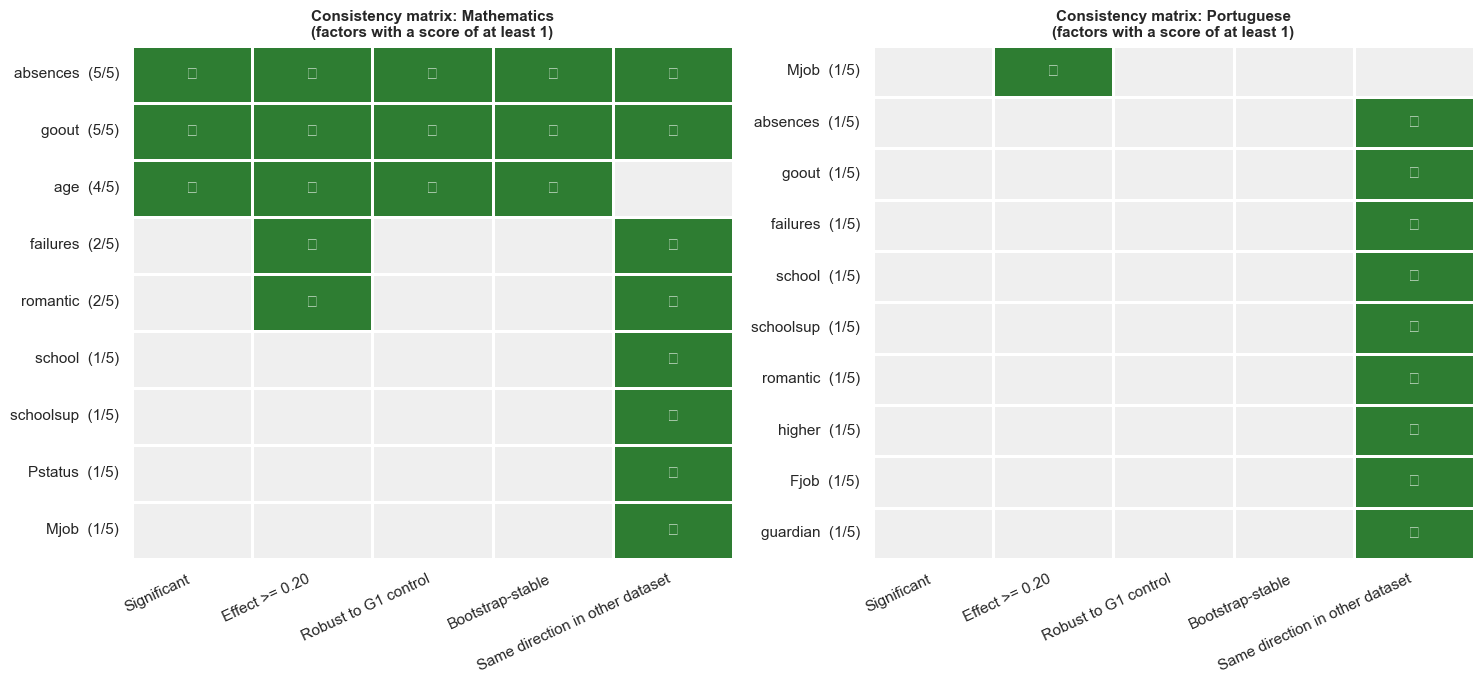

In [14]:
def kodekan_logit(X, f):
    if TIPE[f] == 'nominal':
        urutan = X[f].value_counts().index.tolist()
        D = pd.get_dummies(pd.Categorical(X[f], categories=urutan), prefix=f, drop_first=True, dtype=float)
        D.index = X.index
        return D
    if TIPE[f] == 'numerik':
        return ((X[f] - X[f].mean()) / X[f].std()).astype(float).to_frame(f)
    return X[f].astype(float).to_frame(f)


def logit_kontrol_g1(X, y, g1, aktif):
    y = np.asarray(y).astype(int)
    dasar = pd.DataFrame({'const': 1.0, 'G1': np.asarray(g1, dtype=float)}, index=X.index)
    m0 = sm.Logit(y, dasar).fit(disp=0)
    rows = []
    for f in aktif:
        D = kodekan_logit(X, f)
        rec = dict(faktor=f, OR_kontrol_G1=np.nan, p_LR=np.nan)
        try:
            m1 = sm.Logit(y, pd.concat([dasar, D], axis=1)).fit(disp=0, maxiter=200)
            rec['p_LR'] = float(stats.chi2.sf(max(0.0, 2 * (m1.llf - m0.llf)), D.shape[1]))
            if D.shape[1] == 1:
                rec['OR_kontrol_G1'] = float(np.exp(m1.params[f]))
        except Exception:
            pass
        rows.append(rec)
    T = pd.DataFrame(rows)
    ok = T.p_LR.notna()
    T['q_LR'] = np.nan
    T.loc[ok, 'q_LR'] = multipletests(T.loc[ok, 'p_LR'], method='fdr_bh')[1]
    return T


LAPIS = ['Significant', 'Effect >= 0.20', 'Robust to G1 control', 'Bootstrap-stable', 'Same direction in other dataset']

for nama, H in HASIL.items():
    H['logit'] = logit_kontrol_g1(H['X'], H['y'], H['biner'].G1, H['aktif'])

for nama, H in HASIL.items():
    T = H['uji'].merge(H['logit'], on='faktor').set_index('faktor')
    eo = HASIL[LAIN[nama]]['uji'].set_index('faktor').efek.reindex(T.index).to_numpy()
    bertanda = (T.tipe != 'nominal').to_numpy()
    tanda = np.sign(T.efek.to_numpy())
    r_min = CONFIG['EFEK_REPLIKASI']
    M = pd.DataFrame(index=T.index)
    M[LAPIS[0]] = (T.q < A).to_numpy()
    M[LAPIS[1]] = (T.efek_abs >= E).to_numpy()
    arah_or = np.where(bertanda, np.sign(np.log(T.OR_kontrol_G1.to_numpy())) == tanda, True)
    M[LAPIS[2]] = (T.q_LR.to_numpy() < A) & arah_or
    M[LAPIS[3]] = (T.stabilitas.to_numpy() >= CONFIG['STABILITAS_MIN'])
    M[LAPIS[4]] = np.where(bertanda, (np.sign(eo) == tanda) & (np.abs(eo) >= r_min), eo >= r_min)
    M = M.fillna(False).astype(bool)
    T['skor'] = M.sum(axis=1).astype(int)
    H['konsistensi'] = M
    H['ringkas'] = T.reset_index().sort_values(['skor', 'efek_abs'], ascending=False).reset_index(drop=True)
    simpan_tabel(H['ringkas'], f'B5_factor_summary_{KODE[nama]}')

    lolos = H['ringkas'][(H['ringkas'].status == 'Passes criteria') & (H['ringkas'].tipe != 'nominal')].faktor.tolist()
    if len(lolos) >= 2:
        C = H['X'][lolos].astype(float).corr(method='spearman')
        H['pasangan_kuat'] = [(a_, b_, C.loc[a_, b_]) for i, a_ in enumerate(lolos) for b_ in lolos[i + 1:]
                              if abs(C.loc[a_, b_]) >= 0.5]
    else:
        H['pasangan_kuat'] = []
    print(f'\n=== {nama}: factors with the highest consistency scores ===')
    display(H['ringkas'][['faktor', 'peran', 'efek', 'q', 'OR_kontrol_G1', 'q_LR', 'stabilitas', 'skor', 'status',
                          'catatan']].head(8).round(3))
    print('Strongly correlated key-factor pairs (|rho| >= 0.5):',
          [(a_, b_, round(v, 2)) for a_, b_, v in H['pasangan_kuat']] or 'none')

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, (nama, H) in zip(axes, HASIL.items()):
    R = H['ringkas']
    R = R[R.skor >= 1].head(15).set_index('faktor')
    Mv = H['konsistensi'].loc[R.index]
    sns.heatmap(Mv.astype(int), ax=ax, cmap=ListedColormap(['#EFEFEF', '#2E7D32']), vmin=0, vmax=1, cbar=False,
                linewidths=0.8, linecolor='white', annot=np.where(Mv.values, '✓', ''), fmt='',
                annot_kws={'color': 'white', 'size': 12, 'weight': 'bold'})
    ax.set_yticks(np.arange(len(R)) + 0.5)
    ax.set_yticklabels([f'{f}  ({R.loc[f, "skor"]}/5)' for f in R.index], rotation=0)
    ax.set_xticklabels(Mv.columns, rotation=25, ha='right')
    ax.set_title(f'Consistency matrix: {nama}\n(factors with a score of at least 1)')
    ax.set_ylabel('')
fig.tight_layout()
simpan(fig, 'B5_consistency_matrix')

## B6. Profiles of Key Factors
**What is done**
- **Comeback-rate bar charts** by factor level for the three factors with the highest consistency scores in Mathematics; the same factors are also shown for Portuguese for comparison. The dashed line represents the average comeback rate.
- **Box plots by category** for the same factors across all four student trajectory categories. The Kruskal–Wallis test in the title includes only categories with at least `MIN_N_KELOMPOK` students, so a small Temporary Comeback group may be shown descriptively only.

**How to read the plots:** bars with small sample sizes have wider uncertainty intervals; focus on the overall pattern rather than a single bar’s value.

Displayed factors: absences, goout, age


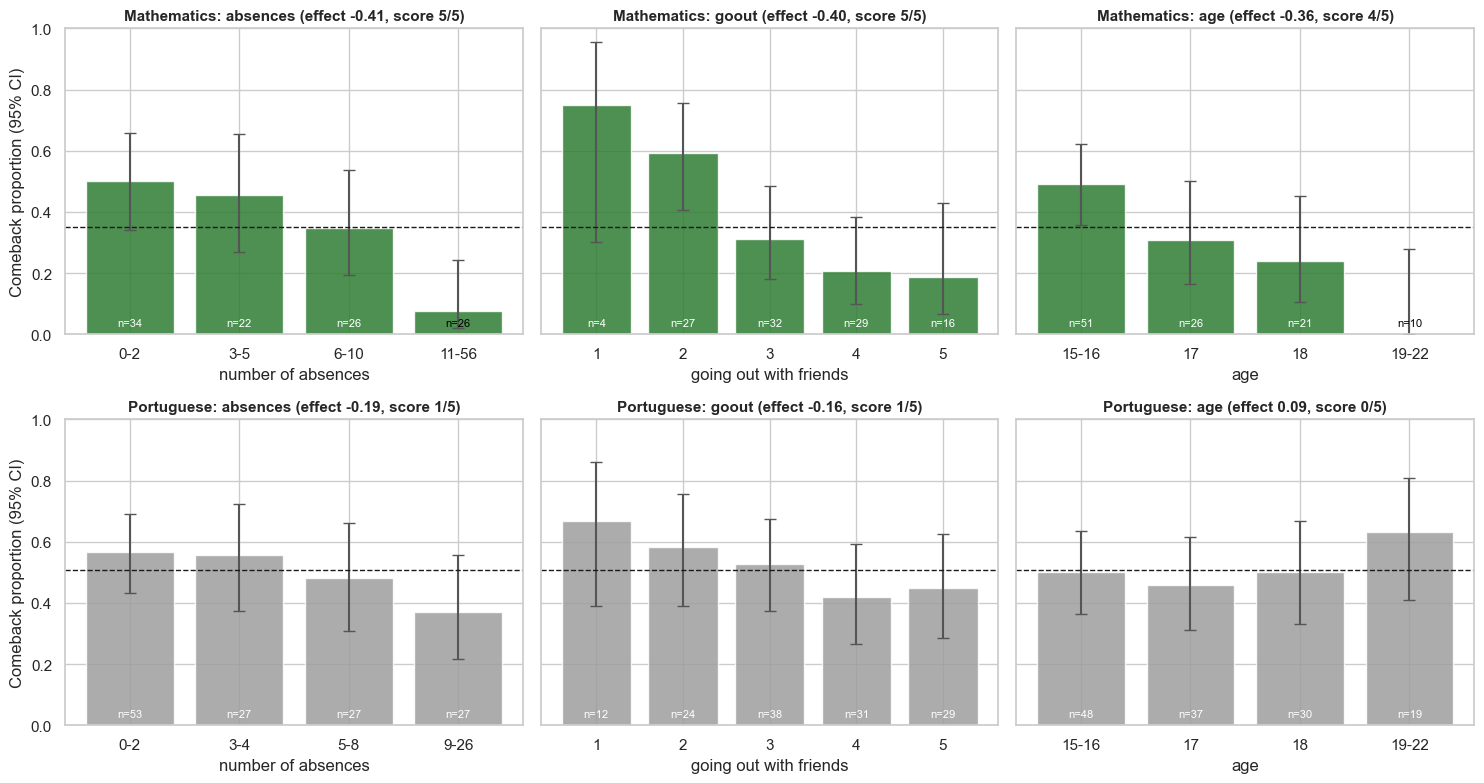

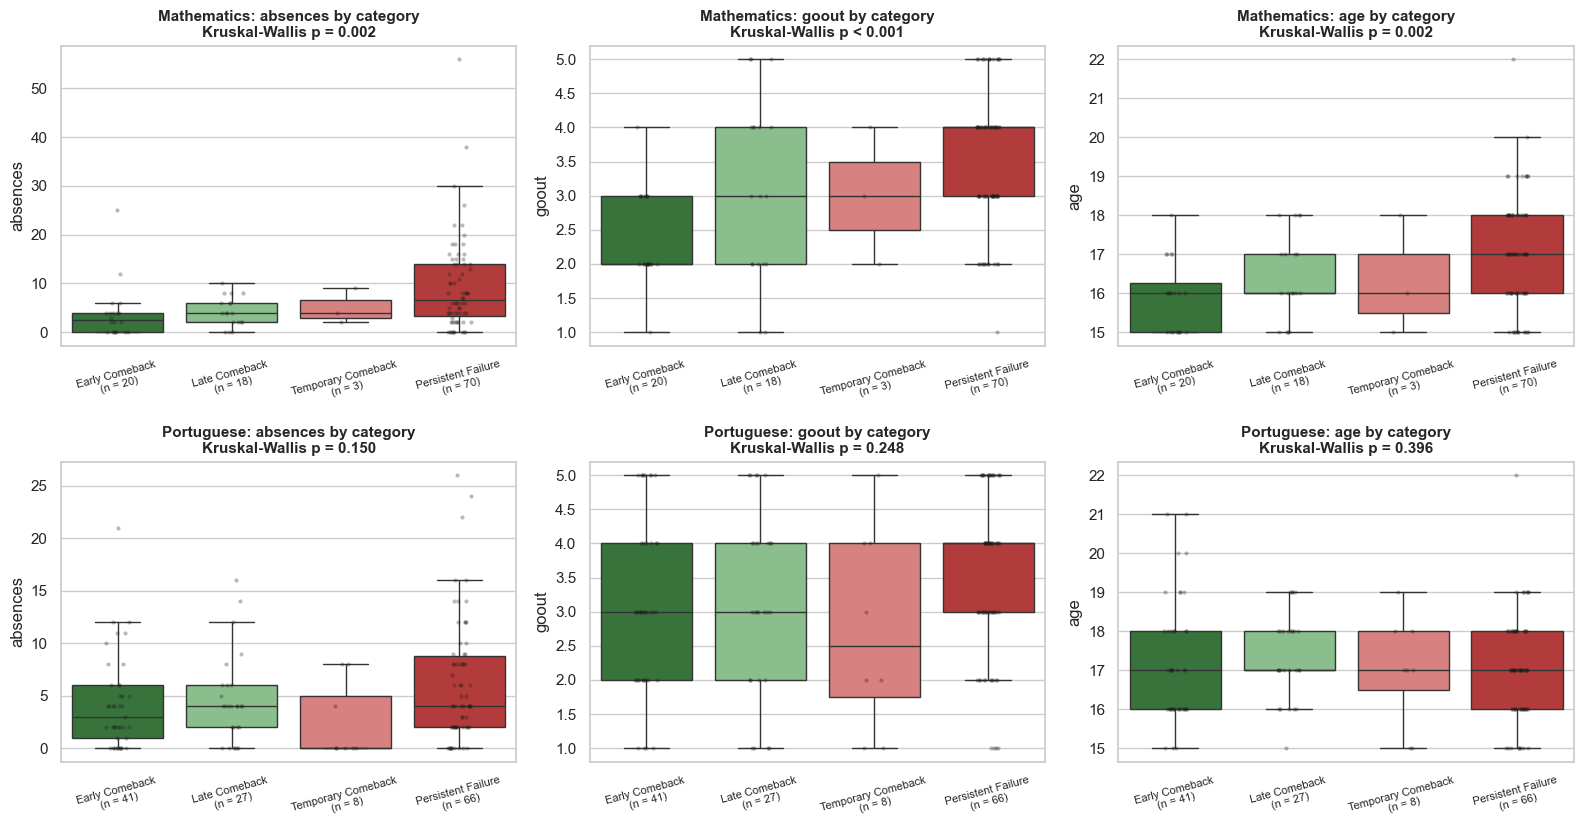

In [15]:
def tingkat_per_level(x, y, f):
    tipe, y = TIPE[f], np.asarray(y).astype(int)
    if tipe == 'numerik':
        kel = pd.qcut(x.astype(float), q=4, duplicates='drop')
        lab = {iv: (f'{int(np.floor(iv.left)) + 1}' if int(np.floor(iv.left)) + 1 == int(np.floor(iv.right))
                    else f'{int(np.floor(iv.left)) + 1}-{int(np.floor(iv.right))}') for iv in kel.cat.categories}
        level, urutan = kel.map(lab).astype(str).to_numpy(), [lab[iv] for iv in kel.cat.categories]
    elif tipe == 'biner':
        level = np.where(np.asarray(x) == 1, LEVEL_POSITIF[f], LEVEL_NEGATIF[f])
        urutan = [LEVEL_NEGATIF[f], LEVEL_POSITIF[f]]
    elif tipe == 'ordinal':
        level = np.asarray(x).astype(int).astype(str)
        urutan = sorted(set(level), key=int)
    else:
        level = np.asarray(x).astype(str)
        urutan = sorted(set(level))
    rows = []
    for lv in urutan:
        m = level == lv
        k, n = int(y[m].sum()), int(m.sum())
        if n:
            lo, hi = proportion_confint(k, n, method='wilson')
            rows.append(dict(level=lv, n=n, laju=k / n, lo=lo, hi=hi))
    return pd.DataFrame(rows)


TOP = [f for f in HASIL['Mathematics']['ringkas'].faktor if TIPE[f] != 'nominal'][:3]
print('Displayed factors:', ', '.join(TOP))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for i, (nama, H) in enumerate(HASIL.items()):
    R = H['ringkas'].set_index('faktor')
    for j, f in enumerate(TOP):
        ax = axes[i, j]
        if f not in H['X'].columns:
            ax.set_axis_off()
            continue
        D = tingkat_per_level(H['X'][f], H['y'], f)
        ax.bar(D.level, D.laju, color=WARNA_STATUS[R.loc[f, 'status']], alpha=0.85,
               yerr=[np.clip(D.laju - D.lo, 0, None), np.clip(D.hi - D.laju, 0, None)], capsize=4, ecolor='#555')
        for k_, (v, n) in enumerate(zip(D.laju, D.n)):
            ax.text(k_, 0.02, f'n={n}', ha='center', va='bottom', fontsize=8, color='white' if v > 0.1 else 'black')
        ax.axhline(H['y'].mean(), ls='--', c='k', lw=1)
        ax.set_ylim(0, 1)
        ax.set_title(f'{nama}: {f} (effect {angka(R.loc[f, "efek"])}, score {R.loc[f, "skor"]}/5)')
        ax.set_xlabel(NAMA[f])
        if j == 0:
            ax.set_ylabel('Comeback proportion (95% CI)')
fig.tight_layout()
simpan(fig, 'B6_comeback_rate_key_factors')

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for i, (nama, H) in enumerate(HASIL.items()):
    f_ = H['fokus']
    urut = [k for k in URUTAN_FOKUS if (f_.kategori == k).any()]
    kat_uji = [k for k in URUTAN_FOKUS if (f_.kategori == k).sum() >= CONFIG['MIN_N_KELOMPOK']]
    for j, f in enumerate(TOP):
        ax = axes[i, j]
        d = pd.DataFrame({'kategori': f_.kategori, 'nilai': f_[f].astype(float) if TIPE[f] != 'biner'
                          else (f_[f] == LEVEL_POSITIF[f]).astype(float)})
        Hs, p = stats.kruskal(*[d.nilai[d.kategori == k] for k in kat_uji])
        if TIPE[f] == 'biner':
            prop = d.groupby('kategori').nilai.mean().reindex(urut)
            ax.bar(range(len(urut)), prop.values, color=[WARNA[k] for k in urut])
            ax.set_ylabel(f'Proporsi {f} = {LEVEL_POSITIF[f]}')
        else:
            sns.boxplot(data=d, x='kategori', y='nilai', order=urut, hue='kategori', hue_order=urut, palette=WARNA,
                        legend=False, showfliers=False, ax=ax)
            sns.stripplot(data=d, x='kategori', y='nilai', order=urut, color='k', alpha=0.3, size=3, ax=ax)
            ax.set_ylabel(f)
        ax.set_xticks(range(len(urut)))
        ax.set_xticklabels(label_kategori(f_, urut), fontsize=8, rotation=15)
        ax.set_xlabel('')
        ax.set_title(f'{nama}: {f} by category\nKruskal-Wallis {teks_p("p", p)}')
fig.tight_layout()
simpan(fig, 'B6_key_factors_by_category')

## B7. Comparing Mathematics and Portuguese
**What is done:** compare each factor’s effect size across the two datasets. The comparison uses **effect sizes rather than p-values** because the sample sizes differ.

| Category | Meaning |
|---|---|
| Consistent | Meets the criteria in both datasets and has the same direction |
| Mathematics-specific / Portuguese-specific | Meets the criteria in only one dataset |
| Opposite directions | Meets the criteria in both, but the directions differ |
| Not significant | Does not meet the criteria in either dataset |

**How to read the chart:** filled points = meets the criteria; hollow points = does not meet the criteria. Grey lines connect the same factor across datasets; a longer line indicates a larger difference between subjects.

,faktor,tipe,efek_mat,status_mat,efek_por,status_por,kategori
0,absences,numerik,-0.406,Passes criteria,-0.185,Not significant,Mathematics-specific
1,goout,ordinal,-0.399,Passes criteria,-0.158,Not significant,Mathematics-specific
2,age,numerik,-0.364,Passes criteria,0.088,Not significant,Mathematics-specific
3,failures,ordinal,-0.212,Not significant,-0.131,Not significant,Not significant
4,romantic,biner,-0.201,Not significant,-0.104,Not significant,Not significant
5,famrel,ordinal,0.170,Not significant,-0.090,Not significant,Not significant
6,school,biner,-0.153,Not significant,-0.121,Not significant,Not significant
7,activities,biner,0.119,Not significant,-0.028,Not significant,Not significant
8,higher,biner,0.115,Not significant,0.074,Not significant,Not significant
9,paid,biner,0.105,Not significant,-0.118,Not significant,Not significant


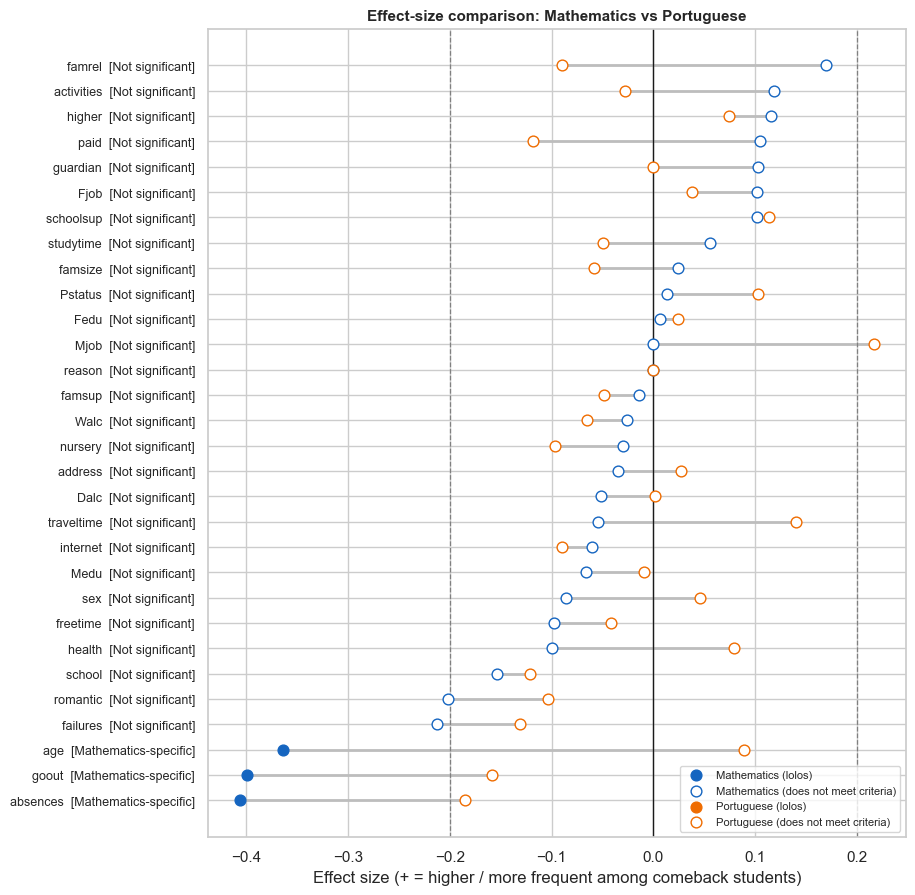

In [16]:
Tm = HASIL['Mathematics']['ringkas'].set_index('faktor')
Tp = HASIL['Portuguese']['ringkas'].set_index('faktor')
rows = []
for f in [f for f in FAKTOR if f in Tm.index or f in Tp.index]:
    em, ep = Tm.efek.get(f, np.nan), Tp.efek.get(f, np.nan)
    lm, lp = Tm.status.get(f) == 'Passes criteria', Tp.status.get(f) == 'Passes criteria'
    searah = TIPE[f] == 'nominal' or np.sign(em) == np.sign(ep)
    kat = ('Consistent' if searah else 'Opposite directions') if (lm and lp) else (
        'Mathematics-specific' if lm else ('Portuguese-specific' if lp else 'Not significant'))
    rows.append(dict(faktor=f, tipe=TIPE[f], efek_mat=em, status_mat=Tm.status.get(f, '-'),
                     efek_por=ep, status_por=Tp.status.get(f, '-'), kategori=kat))
BANDING = pd.DataFrame(rows)
urutan_kat = {k: i for i, k in enumerate(['Consistent', 'Opposite directions', 'Mathematics-specific', 'Portuguese-specific',
                                          'Not significant'])}
BANDING = (BANDING.assign(_u=BANDING.kategori.map(urutan_kat), _e=-BANDING.efek_mat.abs())
           .sort_values(['_u', '_e']).drop(columns=['_u', '_e']).reset_index(drop=True))
display(BANDING.round(3))
simpan_tabel(BANDING, 'B7_mat_vs_por_comparison')

D = BANDING.assign(urut=BANDING.efek_mat.fillna(0)).sort_values('urut').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 10.5))
ypos = np.arange(len(D))
ax.hlines(ypos, D[['efek_mat', 'efek_por']].min(axis=1), D[['efek_mat', 'efek_por']].max(axis=1), color='#BDBDBD', lw=2)
for kol, st, nama in [('efek_mat', 'status_mat', 'Mathematics'), ('efek_por', 'status_por', 'Portuguese')]:
    penuh = (D[st] == 'Passes criteria').to_numpy()
    ax.scatter(D.loc[penuh, kol], ypos[penuh], color=WARNA[nama], s=60, zorder=3, label=f'{nama} (lolos)')
    ax.scatter(D.loc[~penuh, kol], ypos[~penuh], facecolors='white', edgecolors=WARNA[nama], s=60, zorder=3,
               label=f'{nama} (does not meet criteria)')
ax.set_yticks(ypos)
ax.set_yticklabels([f'{f}  [{k}]' for f, k in zip(D.faktor, D.kategori)], fontsize=9)
for v in (-E, E):
    ax.axvline(v, ls='--', c='grey', lw=0.9)
ax.axvline(0, c='k', lw=1)
ax.set_xlabel('Effect size (+ = higher / more frequent among comeback students)')
ax.set_title('Effect-size comparison: Mathematics vs Portuguese')
ax.legend(loc='lower right', fontsize=8)
simpan(fig, 'B7_effect_comparison')

## B8. Simple Risk Profiles
**What is done:** take the two non-nominal factors with the highest consistency scores in Mathematics, divide each into “low” and “high” based on the median among Mathematics students with G1 < 10, and calculate comeback rates for each combination. The same cutoffs are applied to Portuguese for comparison.

**Why:** combine two separate findings into one visual that may be easier for teachers to interpret. The median cutoffs depend only on the factor distributions, not on comeback outcomes.

**How to read the heatmap:** treat cells with small sample sizes as indicative patterns, not precise estimates.

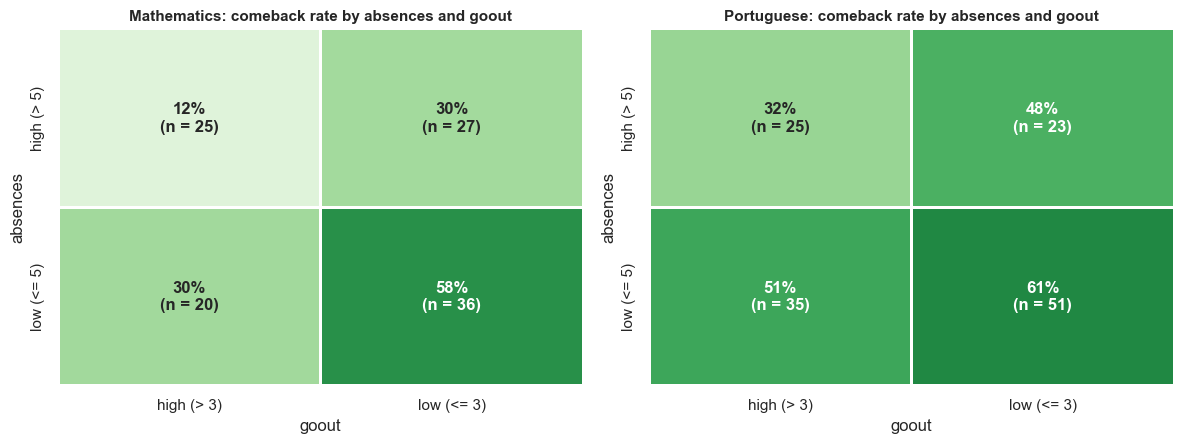

In [17]:
DUA = TOP[:2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
PROFIL = {}
for ax, (nama, H) in zip(axes, HASIL.items()):
    b = H['biner']
    kol = {}
    for f in DUA:
        if TIPE[f] == 'biner':
            kol[f] = np.where(b[f] == LEVEL_POSITIF[f], f'{f} = {LEVEL_POSITIF[f]}', f'{f} = {LEVEL_NEGATIF[f]}')
        else:
            med = HASIL['Mathematics']['fokus'][f].astype(float).median()
            kol[f] = np.where(b[f].astype(float) <= med, f'low (<= {med:g})', f'high (> {med:g})')
    d = pd.DataFrame({DUA[0]: kol[DUA[0]], DUA[1]: kol[DUA[1]], 'comeback': b.comeback.to_numpy()})
    laju = d.pivot_table(index=DUA[0], columns=DUA[1], values='comeback', aggfunc='mean')
    n = d.pivot_table(index=DUA[0], columns=DUA[1], values='comeback', aggfunc='size')
    laju = laju.sort_index().sort_index(axis=1)
    n = n.reindex(index=laju.index, columns=laju.columns).fillna(0)
    PROFIL[nama] = (laju, n)
    annot = np.array([[f'{pct(laju.iloc[r, c])}\n(n = {int(n.iloc[r, c])})' for c in range(laju.shape[1])]
                      for r in range(laju.shape[0])])
    sns.heatmap(laju, annot=annot, fmt='', cmap='Greens', vmin=0, vmax=0.8, cbar=False, ax=ax,
                linewidths=1, linecolor='white', annot_kws={'size': 12, 'weight': 'bold'})
    ax.set_title(f'{nama}: comeback rate by {DUA[0]} and {DUA[1]}')
    ax.set_ylabel(DUA[0])
    ax.set_xlabel(DUA[1])
fig.tight_layout()
simpan(fig, 'B8_risk_profiles')